# 🚌 Bus Passenger-Demand Forecasting — Algions AI Labs project
**How to use:** Google Colab → *Runtime → Run all* (≈ 4–6 min). Part A writes the whole repository into `/content/bus-demand-forecasting`,
Part B is the analysis (EDA → leakage audit → baselines/models → error analysis → explainability → app).
The last cell zips the repo so you can download it and push it to GitHub.

| Part | Sections |
|---|---|
| A. Project setup | 0 |
| B. Analysis | 1 Problem framing · 2 Data & quality · 3 EDA · 4 Leakage audit · 5 Split & features · 6 Train & compare · 7 Error analysis · 8 Uncertainty & capacity flags · 9 Explainability · 10 Robustness · 11 Leakage demo & tests · 12 Inference & app · 13 Limitations · 14 Package |

## 0. Project setup (writes the repository files)

In [1]:
%pip install -q lightgbm gradio
import os, sys
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
PROJECT = Path("/content/bus-demand-forecasting") if IN_COLAB else Path.cwd() / "bus-demand-forecasting"
for d in ["src", "app", "tests", "data/raw", "data/processed", "models", "reports/figures", "notebooks", "docs"]:
    (PROJECT / d).mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT)
print("working in", PROJECT)

Note: you may need to restart the kernel to use updated packages.
working in /tmp/claude-0/-home-claude/5677bd97-9fb0-5a7c-862b-188aeb1937e9/scratchpad/nbrun/bus-demand-forecasting


In [2]:
%%writefile src/__init__.py
# package marker

Writing src/__init__.py


In [3]:
%%writefile tests/__init__.py
# package marker

Writing tests/__init__.py


In [4]:
%%writefile src/config.py
"""Central configuration: paths, dates, split boundaries, thresholds, holiday calendar."""
from pathlib import Path

SEED = 42
ROOT = Path(__file__).resolve().parents[1]


def get_paths(root: Path = ROOT) -> dict:
    root = Path(root)
    return {
        "root": root,
        "raw": root / "data" / "raw" / "bus_trips.csv",
        "history": root / "data" / "processed" / "history.csv",
        "artifact": root / "models" / "forecaster.joblib",
        "reports": root / "reports",
        "figures": root / "reports" / "figures",
    }


# ---- data window and chronological split (test = last quarter, never used for tuning)
START_DATE = "2023-01-01"
END_DATE = "2024-12-31"
TRAIN_END = "2024-06-30"   # train: start+warm-up .. 2024-06-30
VAL_END = "2024-09-30"     # val:   2024-07-01 .. 2024-09-30  (hyper-parameter tuning / early stopping)
#                            test:  2024-10-01 .. 2024-12-31  (touched once, for final reporting)
WARMUP_DAYS = 28           # first 28 days have no 4-week lag history -> not used for modelling

# ---- problem definition
TARGET = "passengers"
HORIZON_DAYS = 2           # forecast is issued 48h before departure
PEAK_HOURS = [(6, 10), (17, 22)]  # [start, end) hours counted as "peak"

# ---- capacity-aware flag thresholds (occupancy = passengers / capacity)
FULL_OCC = 0.90    # predicted occupancy >= 90%  -> ADD_CAPACITY
WATCH_OCC = 0.75   # >= 75% (or P90 reaches capacity) -> WATCH
LOW_OCC = 0.35     # < 35% -> UNDER_USED
HIGH_LOAD_ACTUAL = 0.90  # ground truth definition of a "high-load" trip for flag evaluation

# ---- columns that must NEVER be model inputs (not known at forecast time / are the target)
FORBIDDEN_FEATURES = ["passengers", "revenue_inr", "disruption", "trip_id"]

# ---- public-holiday / festival calendar (date, name, weight). Approximate dates, used for synthetic data.
HOLIDAYS = [
    # 2023
    ("2023-01-15", "Pongal", 1.0), ("2023-01-26", "Republic Day", 0.5), ("2023-03-08", "Holi", 0.7),
    ("2023-04-22", "Eid al-Fitr", 0.8), ("2023-08-15", "Independence Day", 0.5),
    ("2023-09-19", "Ganesh Chaturthi", 0.8), ("2023-10-02", "Gandhi Jayanti", 0.5),
    ("2023-10-24", "Dussehra", 1.0), ("2023-11-12", "Diwali", 1.5), ("2023-12-25", "Christmas", 0.8),
    ("2023-12-31", "New Year's Eve", 0.6),
    # 2024
    ("2024-01-15", "Pongal", 1.0), ("2024-01-26", "Republic Day", 0.5), ("2024-03-25", "Holi", 0.7),
    ("2024-04-11", "Eid al-Fitr", 0.8), ("2024-08-15", "Independence Day", 0.5),
    ("2024-09-07", "Ganesh Chaturthi", 0.8), ("2024-10-02", "Gandhi Jayanti", 0.5),
    ("2024-10-12", "Dussehra", 1.0), ("2024-11-01", "Diwali", 1.5), ("2024-12-25", "Christmas", 0.8),
    ("2024-12-31", "New Year's Eve", 0.6),
    # 2025 (calendar is known in advance -> allowed for forecasting future dates)
    ("2025-01-14", "Pongal", 1.0), ("2025-01-26", "Republic Day", 0.5), ("2025-03-14", "Holi", 0.7),
    ("2025-03-31", "Eid al-Fitr", 0.8), ("2025-08-15", "Independence Day", 0.5),
    ("2025-08-27", "Ganesh Chaturthi", 0.8), ("2025-10-02", "Gandhi Jayanti", 0.5),
    ("2025-10-02", "Dussehra", 1.0), ("2025-10-20", "Diwali", 1.5), ("2025-12-25", "Christmas", 0.8),
    ("2025-12-31", "New Year's Eve", 0.6),
]

Writing src/config.py


In [5]:
%%writefile src/data_prep.py
"""Loading, cleaning and chronological splitting."""
import numpy as np
import pandas as pd

from .config import WARMUP_DAYS


def to_dt(s) -> pd.Series:
    """Parse to a consistent datetime64[ns], midnight-normalised (avoids pandas 2/3 unit mismatches)."""
    return pd.to_datetime(s).dt.normalize().astype("datetime64[ns]")


def load_raw(path) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["date"] = to_dt(df["date"])
    return df


def clean(df: pd.DataFrame):
    """Data-quality fixes. Returns (clean_df, report). Missing fares are imputed later (train-only statistics)."""
    report = {"rows_raw": int(len(df))}
    df = df.copy()

    dup = df.duplicated("trip_id", keep="first")
    report["duplicate_trips_removed"] = int(dup.sum())
    df = df[~dup]

    neg = df["passengers"] < 0
    report["negative_passengers_removed"] = int(neg.sum())
    df = df[~neg].copy()

    # impossible value (more boarded than seats): the true count is unknown, so drop it - clipping would invent a label
    over = df["passengers"] > df["capacity"]
    report["over_capacity_removed"] = int(over.sum())
    df = df[~over].copy()

    report["missing_fare_rows(imputed_later)"] = int(df["fare_inr"].isna().sum())
    report["rows_clean"] = int(len(df))
    df = df.sort_values(["date", "route_id", "departure_time"]).reset_index(drop=True)
    return df, report


def split_masks(df: pd.DataFrame, train_end, val_end, warmup_days: int = WARMUP_DAYS) -> dict:
    """Chronological split by calendar date. Rows in the warm-up window (no lag history) are excluded."""
    train_end, val_end = pd.Timestamp(train_end), pd.Timestamp(val_end)
    first_usable = df["date"].min() + pd.Timedelta(days=warmup_days)
    usable = df["date"] >= first_usable
    return {
        "train": usable & (df["date"] <= train_end),
        "val": usable & (df["date"] > train_end) & (df["date"] <= val_end),
        "test": usable & (df["date"] > val_end),
    }

Writing src/data_prep.py


In [6]:
%%writefile src/generate_data.py
"""Synthetic bus-trip generator (fully reproducible with a seed).

Each row is one scheduled trip: (route, departure date, departure time).
Demand is built from interpretable factors (slot, weekday, month/season, holiday run-up, growth)
with multiplicative noise + Poisson sampling, then capped at bus capacity (boarded passengers can never
exceed seats -> demand is *censored* when a bus sells out). Random disruptions (strikes, floods) cut demand.
Deliberate data-quality problems are injected so the cleaning step has real work to do.
No personal data is generated: every row is an aggregate trip count.
"""
import argparse

import numpy as np
import pandas as pd

from .config import END_DATE, HOLIDAYS, SEED, START_DATE, get_paths

ROUTES = [
    dict(route_id="R01", route_name="Bengaluru - Chennai", route_type="intercity", distance_km=350, capacity=45,
         base=30, growth=0.10, fare_per_km=1.6,
         slots=[("06:00", 0.9), ("09:30", 0.7), ("14:00", 0.6), ("21:00", 1.3), ("22:30", 1.2)]),
    dict(route_id="R02", route_name="Bengaluru - Hyderabad", route_type="intercity", distance_km=570, capacity=45,
         base=32, growth=0.12, fare_per_km=1.5,
         slots=[("18:30", 1.0), ("20:00", 1.3), ("21:30", 1.2)]),
    dict(route_id="R03", route_name="Mumbai - Pune", route_type="commuter", distance_km=150, capacity=52,
         base=30, growth=0.06, fare_per_km=1.4,
         slots=[("06:00", 1.2), ("07:30", 1.3), ("09:00", 1.0), ("12:00", 0.6), ("17:00", 1.2), ("18:30", 1.3),
                ("20:00", 0.9)]),
    dict(route_id="R04", route_name="Delhi - Jaipur", route_type="intercity", distance_km=280, capacity=45,
         base=28, growth=0.08, fare_per_km=1.5,
         slots=[("06:00", 1.0), ("08:00", 0.9), ("14:00", 0.7), ("22:00", 1.2)]),
    dict(route_id="R05", route_name="Hyderabad - Vijayawada", route_type="intercity", distance_km=275, capacity=45,
         base=27, growth=0.07, fare_per_km=1.4,
         slots=[("07:00", 0.9), ("13:00", 0.7), ("19:00", 1.2), ("22:30", 1.3)]),
    dict(route_id="R06", route_name="Chennai - Coimbatore", route_type="intercity", distance_km=500, capacity=40,
         base=26, growth=0.11, fare_per_km=1.6,
         slots=[("20:00", 1.2), ("21:30", 1.3), ("23:00", 1.0)]),
    dict(route_id="R07", route_name="Pune - Goa", route_type="tourist", distance_km=450, capacity=40,
         base=30, growth=0.15, fare_per_km=1.8,
         slots=[("17:00", 1.0), ("19:00", 1.3), ("21:00", 1.1)]),
    dict(route_id="R08", route_name="Ahmedabad - Surat", route_type="commuter", distance_km=265, capacity=52,
         base=28, growth=0.05, fare_per_km=1.3,
         slots=[("06:30", 1.1), ("09:00", 0.9), ("12:30", 0.6), ("17:30", 1.2), ("19:30", 1.0)]),
]

DOW = {  # Mon..Sun multipliers
    "commuter": [1.15, 1.05, 1.00, 1.05, 1.20, 0.70, 0.80],
    "intercity": [0.95, 0.85, 0.85, 0.95, 1.25, 1.15, 1.20],
    "tourist": [0.55, 0.55, 0.60, 0.80, 1.55, 1.60, 1.05],
}
MONTH = {  # Jan..Dec multipliers
    "commuter": [1.00, 1.00, 0.95, 0.90, 0.90, 1.00, 1.00, 1.00, 1.05, 1.10, 1.10, 1.05],
    "intercity": [1.00, 0.95, 1.05, 1.15, 1.15, 0.95, 0.90, 0.90, 0.95, 1.10, 1.10, 1.05],
    "tourist": [1.10, 0.90, 1.10, 1.40, 1.50, 0.70, 0.60, 0.65, 0.80, 1.00, 1.10, 1.50],
}
DEMAND_SCALE = 0.78  # global calibration so that only true peaks/festivals sell out
HOL_TYPE_MULT = {"commuter": 0.3, "intercity": 1.0, "tourist": 1.4}
HOL_OFFSET_EFFECT = {-3: 0.10, -2: 0.25, -1: 0.40, 0: -0.10, 1: 0.25, 2: 0.10}  # days relative to holiday


def _holiday_effect(dates: pd.DatetimeIndex) -> dict:
    """Sum of weighted run-up/return effects per calendar date."""
    hol = [(pd.Timestamp(d), w) for d, _, w in HOLIDAYS]
    out = {}
    for d in dates:
        eff = 0.0
        for h, w in hol:
            off = (d - h).days
            if off in HOL_OFFSET_EFFECT:
                eff += w * HOL_OFFSET_EFFECT[off]
        out[d] = eff
    return out


def generate_dataset(start=START_DATE, end=END_DATE, seed=SEED, inject_quality_issues=True) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start, end, freq="D")
    n_days = len(dates)

    slot_rows = []
    for ri, r in enumerate(ROUTES):
        for t, w in r["slots"]:
            slot_rows.append({**{k: r[k] for k in ("route_id", "route_name", "route_type", "distance_km", "capacity",
                                                    "base", "growth", "fare_per_km")},
                              "route_idx": ri, "departure_time": t, "slot_w": w})
    df = pd.DataFrame(slot_rows).merge(pd.DataFrame({"date": dates}), how="cross")
    df = df.sort_values(["date", "route_id", "departure_time"]).reset_index(drop=True)

    dow = df["date"].dt.dayofweek.to_numpy()
    month = df["date"].dt.month.to_numpy()
    hour = df["departure_time"].str.slice(0, 2).astype(int).to_numpy()
    t_days = (df["date"] - dates[0]).dt.days.to_numpy()
    rtype = df["route_type"].to_numpy()

    dow_f = np.ones(len(df)); month_f = np.ones(len(df)); hol_mult = np.ones(len(df))
    for ty in DOW:
        m = rtype == ty
        dow_f[m] = np.array(DOW[ty])[dow[m]]
        month_f[m] = np.array(MONTH[ty])[month[m] - 1]
        hol_mult[m] = HOL_TYPE_MULT[ty]
    hol_eff = df["date"].map(_holiday_effect(dates)).to_numpy()
    hol_f = np.clip(1 + hol_mult * hol_eff, 0.5, None)

    # route-type specific slot x weekday interactions (commuter peaks: Monday morning, Friday/Sunday evening)
    inter = np.ones(len(df))
    comm = rtype == "commuter"
    inter[comm & (hour < 10) & (dow == 0)] = 1.25
    inter[comm & (hour >= 17) & np.isin(dow, [4, 6])] = 1.25

    growth_f = 1 + df["growth"].to_numpy() * t_days / 365.0

    # disruptions: statewide event days + route-specific events (unpredictable at forecast time)
    glob_day = rng.random(n_days) < 0.008
    route_day = rng.random((n_days, len(ROUTES))) < 0.02
    route_cut = rng.uniform(0.3, 0.7, size=(n_days, len(ROUTES)))
    di, ri = t_days, df["route_idx"].to_numpy()
    disruption = glob_day[di] | route_day[di, ri]
    disr_f = np.ones(len(df))
    disr_f[route_day[di, ri]] = route_cut[di, ri][route_day[di, ri]]
    disr_f[glob_day[di]] = 0.5

    mu = DEMAND_SCALE * df["base"].to_numpy() * df["slot_w"].to_numpy() * dow_f * month_f * hol_f * inter * growth_f * disr_f
    mu = mu * rng.lognormal(0.0, 0.10, size=len(df))
    demand = rng.poisson(mu)
    passengers = np.minimum(demand, df["capacity"].to_numpy())  # censoring at capacity

    is_weekend = dow >= 5
    fare = df["fare_per_km"].to_numpy() * df["distance_km"].to_numpy() * (
        1 + 0.10 * is_weekend + 0.5 * np.clip(hol_f - 1, 0, None))
    fare = np.round(fare / 10) * 10

    out = pd.DataFrame({
        "trip_id": df["route_id"] + "_" + df["date"].dt.strftime("%Y%m%d") + "_" + df["departure_time"].str.replace(":", ""),
        "route_id": df["route_id"], "route_name": df["route_name"], "route_type": df["route_type"],
        "distance_km": df["distance_km"], "capacity": df["capacity"], "date": df["date"],
        "departure_time": df["departure_time"], "fare_inr": fare, "passengers": passengers.astype(int),
        "revenue_inr": passengers * fare,        # post-hoc column: deliberately a LEAKAGE TRAP
        "disruption": disruption.astype(int),    # known only after the fact: also excluded from features
    })

    # data-feed outage: no records for R05 for five days
    outage = (out["route_id"] == "R05") & (out["date"] >= "2024-03-10") & (out["date"] <= "2024-03-14")
    out = out[~outage].reset_index(drop=True)

    if inject_quality_issues:
        n = len(out)
        out["date"] = out["date"].dt.strftime("%Y-%m-%d")
        out.loc[rng.choice(n, int(0.005 * n), replace=False), "fare_inr"] = np.nan          # missing fares
        over = rng.choice(n, int(0.001 * n), replace=False)                                  # over-capacity glitches
        out.loc[over, "passengers"] = out.loc[over, "capacity"] + rng.integers(3, 15, size=len(over))
        neg = rng.choice(n, int(0.0005 * n), replace=False)                                  # sensor errors
        out.loc[neg, "passengers"] = -1
        dups = out.sample(int(0.0015 * n), random_state=seed)                                # duplicate rows
        out = pd.concat([out, dups], ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    else:
        out["date"] = out["date"].dt.strftime("%Y-%m-%d")
    return out


def main():
    ap = argparse.ArgumentParser(description="Generate the synthetic bus-trip dataset")
    ap.add_argument("--out", default=str(get_paths()["raw"]))
    ap.add_argument("--seed", type=int, default=SEED)
    a = ap.parse_args()
    df = generate_dataset(seed=a.seed)
    from pathlib import Path
    Path(a.out).parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(a.out, index=False)
    print(f"wrote {len(df):,} rows -> {a.out}")


if __name__ == "__main__":
    main()

Writing src/generate_data.py


In [7]:
%%writefile src/features.py
"""Leakage-safe feature engineering.

Forecast origin: 48 hours (HORIZON_DAYS) before departure. Allowed inputs:
  * route / schedule attributes (route, capacity, distance, departure time, fare set by the pricing rule)
  * calendar (weekday, month, season, holiday calendar - all known far in advance)
  * demand history of the SAME route+slot at least 7 days earlier (>= horizon, so always observed)
Forbidden: passengers (target), revenue_inr (computed from target), disruption (known only afterwards).
"""
import numpy as np
import pandas as pd

from .config import FORBIDDEN_FEATURES, HOLIDAYS, PEAK_HOURS
from .data_prep import to_dt

HOL_CAP = 15
_HOL = sorted((pd.Timestamp(d), w) for d, _, w in HOLIDAYS)
HOL_DATES = np.array([d for d, _ in _HOL], dtype="datetime64[D]")
HOL_W = np.array([w for _, w in _HOL])
SEASONS = ["winter", "summer", "monsoon", "festive"]
SEASON_OF_MONTH = {12: "winter", 1: "winter", 2: "winter", 3: "summer", 4: "summer", 5: "summer",
                   6: "monsoon", 7: "monsoon", 8: "monsoon", 9: "monsoon", 10: "festive", 11: "festive"}
ROUTE_TYPES = ["commuter", "intercity", "tourist"]
LAG_COLS = ["lag_w1", "lag_w2", "lag_w3", "lag_w4"]
KEYS = ["route_id", "departure_time", "date"]

NUMERIC_FEATURES = [
    "capacity", "distance_km", "fare_inr", "dep_hour", "is_peak",
    "dow", "is_weekend", "month", "doy", "dow_sin", "dow_cos", "doy_sin", "doy_cos",
    "is_holiday", "days_to_next_holiday", "next_holiday_weight", "days_since_prev_holiday", "prev_holiday_weight",
    "lag_w1", "lag_w2", "lag_w3", "lag_w4", "lag_mean_4",
]


def holiday_features(dates: pd.Series) -> pd.DataFrame:
    d = dates.to_numpy().astype("datetime64[D]")
    n = len(HOL_DATES)
    i_next = np.searchsorted(HOL_DATES, d, side="left")       # first holiday >= d
    i_prev = np.searchsorted(HOL_DATES, d, side="left") - 1   # last holiday  <  d
    nxt = np.minimum(i_next, n - 1)
    prv = np.maximum(i_prev, 0)
    days_next = np.where(i_next < n, (HOL_DATES[nxt] - d).astype(int), HOL_CAP)
    days_prev = np.where(i_prev >= 0, (d - HOL_DATES[prv]).astype(int), HOL_CAP)
    return pd.DataFrame({
        "is_holiday": (days_next == 0).astype(int),
        "days_to_next_holiday": np.minimum(days_next, HOL_CAP),
        "next_holiday_weight": np.where(days_next < HOL_CAP, HOL_W[nxt], 0.0),
        "days_since_prev_holiday": np.minimum(days_prev, HOL_CAP),
        "prev_holiday_weight": np.where(days_prev < HOL_CAP, HOL_W[prv], 0.0),
    }, index=dates.index)


def add_lag_features(df: pd.DataFrame, history: pd.DataFrame, start_week: int = 1, n_weeks: int = 4) -> pd.DataFrame:
    """Same route+slot demand 7*start_week, 7*(start_week+1)... days BEFORE each row's date.
    start_week=1 -> exactly last week (always known at a 48h horizon). A larger start_week is used at inference
    when the history is stale (forecast date more than a week beyond the last observed day)."""
    out = df[KEYS].copy()
    out["_row"] = np.arange(len(out))
    h = history[KEYS + ["passengers"]].drop_duplicates(KEYS)
    for w in range(1, n_weeks + 1):
        shifted = h.assign(date=h["date"] + pd.Timedelta(days=7 * (start_week + w - 1)))
        shifted = shifted.rename(columns={"passengers": f"lag_w{w}"})
        out = out.merge(shifted, on=KEYS, how="left")
    out = out.sort_values("_row")
    res = out[LAG_COLS].copy()
    res.index = df.index
    res["lag_mean_4"] = res[LAG_COLS].mean(axis=1)
    return res


class FeatureBuilder:
    """Fit on training data only (learns route table + median fares); transform anything."""

    def fit(self, df: pd.DataFrame):
        r = df.drop_duplicates("route_id")[["route_id", "route_name", "route_type", "distance_km", "capacity"]]
        self.routes_ = r.set_index("route_id").sort_index()
        self.route_ids_ = list(self.routes_.index)
        self.slots_ = {k: sorted(v) for k, v in df.groupby("route_id")["departure_time"].unique().items()}
        self.fare_median_ = df.groupby("route_id")["fare_inr"].median()
        return self

    @property
    def feature_names(self):
        return (NUMERIC_FEATURES + [f"route_{r}" for r in self.route_ids_]
                + [f"type_{t}" for t in ROUTE_TYPES] + [f"season_{s}" for s in SEASONS])

    def transform(self, df: pd.DataFrame, history: pd.DataFrame, start_week: int = 1) -> pd.DataFrame:
        d = to_dt(df["date"])
        X = pd.DataFrame(index=df.index)
        rid = df["route_id"]
        X["capacity"] = rid.map(self.routes_["capacity"]).astype(float)
        X["distance_km"] = rid.map(self.routes_["distance_km"]).astype(float)
        fare = df["fare_inr"] if "fare_inr" in df.columns else pd.Series(np.nan, index=df.index)
        X["fare_inr"] = fare.fillna(rid.map(self.fare_median_)).astype(float)
        hh = df["departure_time"].str.slice(0, 2).astype(int)
        mm = df["departure_time"].str.slice(3, 5).astype(int)
        X["dep_hour"] = hh + mm / 60.0
        X["is_peak"] = sum(((hh >= a) & (hh < b)).astype(int) for a, b in PEAK_HOURS).clip(upper=1)
        X["dow"] = d.dt.dayofweek
        X["is_weekend"] = (X["dow"] >= 5).astype(int)
        X["month"] = d.dt.month
        X["doy"] = d.dt.dayofyear
        X["dow_sin"], X["dow_cos"] = np.sin(2 * np.pi * X["dow"] / 7), np.cos(2 * np.pi * X["dow"] / 7)
        X["doy_sin"], X["doy_cos"] = np.sin(2 * np.pi * X["doy"] / 365.25), np.cos(2 * np.pi * X["doy"] / 365.25)
        X = pd.concat([X, holiday_features(d)], axis=1)
        tmp = df[["route_id", "departure_time"]].assign(date=d)
        X = pd.concat([X, add_lag_features(tmp, history, start_week)], axis=1)
        for r in self.route_ids_:
            X[f"route_{r}"] = (rid == r).astype(int)
        rtype = rid.map(self.routes_["route_type"])
        for t in ROUTE_TYPES:
            X[f"type_{t}"] = (rtype == t).astype(int)
        season = d.dt.month.map(SEASON_OF_MONTH)
        for s in SEASONS:
            X[f"season_{s}"] = (season == s).astype(int)
        X = X[self.feature_names]
        assert not set(X.columns) & set(FORBIDDEN_FEATURES), "forbidden column leaked into features"
        return X

Writing src/features.py


In [8]:
%%writefile src/evaluate.py
"""Metrics, breakdowns and capacity-aware flags."""
import numpy as np
import pandas as pd

from .config import FULL_OCC, LOW_OCC, WATCH_OCC


def regression_metrics(y, p) -> dict:
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = y - p
    return {"MAE": float(np.mean(np.abs(e))), "RMSE": float(np.sqrt(np.mean(e ** 2))),
            "WAPE_%": float(100 * np.abs(e).sum() / y.sum()), "Bias": float(np.mean(p - y))}


def group_metrics(frame: pd.DataFrame, by, y="passengers", p="pred") -> pd.DataFrame:
    rows = []
    for key, g in frame.groupby(by, observed=True):
        rows.append({**(dict(zip(by, key)) if isinstance(by, list) else {by: key}),
                     "n_trips": len(g), **regression_metrics(g[y], g[p])})
    return pd.DataFrame(rows)


def interval_coverage(y, lo, hi) -> float:
    y = np.asarray(y)
    return float(np.mean((y >= np.asarray(lo)) & (y <= np.asarray(hi))))


def capacity_flags(pred, p90, capacity) -> np.ndarray:
    """ADD_CAPACITY / WATCH / NORMAL / UNDER_USED - advisory only, a human approves every action."""
    pred, p90, capacity = (np.asarray(a, float) for a in (pred, p90, capacity))
    occ, hi = pred / capacity, p90 / capacity
    return np.select([occ >= FULL_OCC, (occ >= WATCH_OCC) | (hi >= 1.0), occ < LOW_OCC],
                     ["ADD_CAPACITY", "WATCH", "UNDER_USED"], default="NORMAL")

Writing src/evaluate.py


In [9]:
%%writefile src/train.py
"""Repeatable training pipeline:  python -m src.train   (add --fast for a quick smoke run)

Steps: generate/load data -> clean -> chronological split -> baselines -> Ridge / RandomForest / LightGBM
-> tune LightGBM on VALIDATION only -> refit on train+val -> evaluate ONCE on the held-out TEST set -> save artifact.
"""
import argparse
import json
import random
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from . import config as C
from .data_prep import clean, load_raw, split_masks
from .evaluate import capacity_flags, group_metrics, interval_coverage, regression_metrics
from .features import FeatureBuilder
from .generate_data import generate_dataset

warnings.filterwarnings("ignore", message=".*eval_set.*")
warnings.filterwarnings("ignore", category=UserWarning, module="lightgbm")


# ----------------------------------------------------------------------------- baselines
class HistoricalBaseline:
    """Mean demand by (route, departure time, weekday); falls back to (route, time) then global mean."""

    def fit(self, df):
        df = df.assign(dow=df["date"].dt.dayofweek)
        self.full_ = df.groupby(["route_id", "departure_time", "dow"])[C.TARGET].mean()
        self.slot_ = df.groupby(["route_id", "departure_time"])[C.TARGET].mean()
        self.global_ = float(df[C.TARGET].mean())
        return self

    def predict(self, df):
        idx = pd.MultiIndex.from_arrays([df["route_id"], df["departure_time"], df["date"].dt.dayofweek])
        p = pd.Series(self.full_.reindex(idx).to_numpy(), index=df.index)
        idx2 = pd.MultiIndex.from_arrays([df["route_id"], df["departure_time"]])
        p = p.fillna(pd.Series(self.slot_.reindex(idx2).to_numpy(), index=df.index)).fillna(self.global_)
        return p.to_numpy()


def seasonal_naive(X, fallback):
    """Same route+slot, same weekday last week; falls back to the historical baseline if missing."""
    return X["lag_w1"].fillna(pd.Series(fallback, index=X.index)).to_numpy()


# ----------------------------------------------------------------------------- models
def make_ridge(alpha=10.0):
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", Ridge(alpha=alpha))])


def make_rf(fast=False):
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("m", RandomForestRegressor(n_estimators=40 if fast else 300, min_samples_leaf=3, max_features=0.5,
                                                 n_jobs=-1, random_state=C.SEED))])


LGB_SPACE = dict(num_leaves=[15, 31, 63], learning_rate=[0.03, 0.05, 0.1], min_child_samples=[10, 20, 50, 100],
                 colsample_bytree=[0.6, 0.8, 1.0], subsample=[0.7, 0.9, 1.0], reg_lambda=[0, 1, 5, 10])


def make_lgbm(params, n_estimators, objective="regression", alpha=None):
    kw = dict(objective=objective, n_estimators=n_estimators, subsample_freq=1, random_state=C.SEED,
              n_jobs=-1, verbose=-1, deterministic=True, force_row_wise=True, **params)
    if alpha is not None:
        kw["alpha"] = alpha
    return lgb.LGBMRegressor(**kw)


def tune_lgbm(Xtr, ytr, Xva, yva, n_iter=20, seed=C.SEED):
    """Random search; early stopping + selection on the VALIDATION set only."""
    rng, rows = random.Random(seed), []
    for _ in range(n_iter):
        p = {k: rng.choice(v) for k, v in LGB_SPACE.items()}
        m = lgb.LGBMRegressor(objective="regression", metric="l1", n_estimators=2000, subsample_freq=1,
                              random_state=seed, n_jobs=-1, verbose=-1, deterministic=True, force_row_wise=True, **p)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(100, verbose=False)])
        rows.append({**p, "best_iter": int(m.best_iteration_),
                     "val_MAE": float(np.mean(np.abs(yva - m.predict(Xva))))})
    res = pd.DataFrame(rows).sort_values("val_MAE").reset_index(drop=True)
    best = {k: res.loc[0, k] for k in LGB_SPACE}
    best = {k: (int(v) if isinstance(v, (np.integer,)) else float(v) if isinstance(v, (np.floating,)) else v)
            for k, v in best.items()}
    return best, int(res.loc[0, "best_iter"]), res


# ----------------------------------------------------------------------------- pipeline
def run(root=C.ROOT, fast=False, verbose=True, data_start=C.START_DATE, data_end=C.END_DATE,
        train_end=C.TRAIN_END, val_end=C.VAL_END, save=True):
    paths = C.get_paths(root)
    log = print if verbose else (lambda *a, **k: None)

    if not paths["raw"].exists():
        paths["raw"].parent.mkdir(parents=True, exist_ok=True)
        generate_dataset(data_start, data_end).to_csv(paths["raw"], index=False)
        log(f"generated synthetic data -> {paths['raw']}")
    raw = load_raw(paths["raw"])
    df, dq = clean(raw)
    log("data-quality report:", dq)

    m = split_masks(df, train_end, val_end)
    tr, va, te = df[m["train"]], df[m["val"]], df[m["test"]]
    log(f"rows  train={len(tr):,}  val={len(va):,}  test={len(te):,}")
    y = df[C.TARGET]

    # --- stage 1: tuning on train -> validation
    fb = FeatureBuilder().fit(tr)
    X = fb.transform(df, history=df)
    base_val = HistoricalBaseline().fit(tr).predict(va)
    cand = {"Ridge": make_ridge().fit(X[m["train"]], y[m["train"]]),
            "RandomForest": make_rf(fast).fit(X[m["train"]], y[m["train"]])}
    val_scores = {"Baseline: route/time/weekday mean": regression_metrics(va[C.TARGET], base_val)}
    for name, mdl in cand.items():
        val_scores[name] = regression_metrics(va[C.TARGET], mdl.predict(X[m["val"]]))
    best, best_iter, tuning = tune_lgbm(X[m["train"]], y[m["train"]], X[m["val"]], y[m["val"]],
                                        n_iter=4 if fast else 20)
    lgb_val = make_lgbm(best, best_iter).fit(X[m["train"]], y[m["train"]])
    val_scores["LightGBM (tuned)"] = regression_metrics(va[C.TARGET], lgb_val.predict(X[m["val"]]))
    log("best LightGBM params:", best, "iters:", best_iter)

    # --- stage 2: refit on train+val, evaluate once on test
    trva_mask = m["train"] | m["val"]
    trva = df[trva_mask]
    fb2 = FeatureBuilder().fit(trva)
    X2 = fb2.transform(df, history=df)
    n_final = int(best_iter * 1.15)
    models = {
        "Ridge": make_ridge().fit(X2[trva_mask], y[trva_mask]),
        "RandomForest": make_rf(fast).fit(X2[trva_mask], y[trva_mask]),
        "LightGBM (tuned)": make_lgbm(best, n_final).fit(X2[trva_mask], y[trva_mask]),
    }
    q10 = make_lgbm(best, n_final, "quantile", 0.10).fit(X2[trva_mask], y[trva_mask])
    q90 = make_lgbm(best, n_final, "quantile", 0.90).fit(X2[trva_mask], y[trva_mask])
    base = HistoricalBaseline().fit(trva)

    Xte, yte = X2[m["test"]], y[m["test"]]
    preds = {"Baseline: route/time/weekday mean": base.predict(te)}
    preds["Baseline: same slot last week"] = seasonal_naive(Xte, preds["Baseline: route/time/weekday mean"])
    for name, mdl in models.items():
        preds[name] = mdl.predict(Xte)
    test_scores = {k: regression_metrics(yte, np.clip(v, 0, te["capacity"].to_numpy())) for k, v in preds.items()}

    lo, hi = np.minimum(q10.predict(Xte), preds["LightGBM (tuned)"]), np.maximum(q90.predict(Xte), preds["LightGBM (tuned)"])
    lo, hi = np.clip(lo, 0, te["capacity"]), np.clip(hi, 0, te["capacity"])
    cov = interval_coverage(yte, lo, hi)

    out = te[["trip_id", "route_id", "date", "departure_time", "capacity", C.TARGET, "disruption"]].copy()
    out["pred"] = np.clip(preds["LightGBM (tuned)"], 0, te["capacity"].to_numpy())
    out["pred_baseline"] = preds["Baseline: route/time/weekday mean"]
    out["p10"], out["p90"] = lo, hi
    out["is_peak"] = Xte["is_peak"].to_numpy()
    out["flag"] = capacity_flags(out["pred"], out["p90"], out["capacity"])

    results = {"data_quality": dq, "val_scores": val_scores, "test_scores": test_scores,
               "interval_coverage_80": cov, "mean_interval_width": float((hi - lo).mean()),
               "best_params": best, "n_estimators_final": n_final,
               "split": {"train_end": train_end, "val_end": val_end, "data_end": data_end,
                         "n_train": int(len(tr)), "n_val": int(len(va)), "n_test": int(len(te))}}
    if save:
        paths["artifact"].parent.mkdir(parents=True, exist_ok=True)
        paths["history"].parent.mkdir(parents=True, exist_ok=True)
        paths["reports"].mkdir(parents=True, exist_ok=True)
        joblib.dump({"builder": fb2, "point": models["LightGBM (tuned)"], "q10": q10, "q90": q90,
                     "feature_names": fb2.feature_names, "meta": results}, paths["artifact"])
        df.to_csv(paths["history"], index=False)
        out.to_csv(paths["reports"] / "test_predictions.csv", index=False)
        tuning.to_csv(paths["reports"] / "lgbm_tuning.csv", index=False)
        (paths["reports"] / "metrics.json").write_text(json.dumps(results, indent=2, default=str))
        log(f"saved artifact -> {paths['artifact']}")
    log(pd.DataFrame(test_scores).T.round(2).to_string())
    return {"df": df, "X": X2, "masks": m, "models": models, "q10": q10, "q90": q90, "fb": fb2, "baseline": base,
            "test_out": out, "preds": preds, "results": results, "tuning": tuning, "val_X": X, "paths": paths}


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--fast", action="store_true", help="small/quick run for smoke tests")
    a = ap.parse_args()
    run(fast=a.fast)


if __name__ == "__main__":
    main()

Writing src/train.py


In [10]:
%%writefile src/experiments.py
"""Robustness experiments: rolling-origin backtest and new-route (cold-start) stress test."""
import numpy as np
import pandas as pd

from . import config as C
from .evaluate import regression_metrics
from .features import FeatureBuilder
from .train import HistoricalBaseline, make_lgbm


def rolling_backtest(df, params, n_estimators, cutoffs=("2024-04-01", "2024-07-01", "2024-10-01"), window_days=92):
    """Expanding-window backtest: train on everything before the cutoff, test on the next ~3 months."""
    rows = []
    for c in cutoffs:
        c = pd.Timestamp(c)
        usable = df["date"] >= df["date"].min() + pd.Timedelta(days=C.WARMUP_DAYS)
        tr = usable & (df["date"] < c)
        te = (df["date"] >= c) & (df["date"] < c + pd.Timedelta(days=window_days))
        fb = FeatureBuilder().fit(df[tr])
        X = fb.transform(df, history=df)
        m = make_lgbm(params, n_estimators).fit(X[tr], df.loc[tr, C.TARGET])
        base = HistoricalBaseline().fit(df[tr]).predict(df[te])
        y = df.loc[te, C.TARGET]
        rows.append({"test_window": f"{c.date()} .. {(c + pd.Timedelta(days=window_days - 1)).date()}",
                     "baseline_WAPE_%": regression_metrics(y, base)["WAPE_%"],
                     "lightgbm_WAPE_%": regression_metrics(y, m.predict(X[te]))["WAPE_%"]})
    return pd.DataFrame(rows)


def cold_start_experiment(df, params, n_estimators, normal_test_out):
    """Hold out each route entirely. The model never saw the route and has no demand history for it
    (route one-hot and lag features removed) -> how bad is a NEW route?"""
    usable = df["date"] >= df["date"].min() + pd.Timedelta(days=C.WARMUP_DAYS)
    fit_mask = usable & (df["date"] <= pd.Timestamp(C.VAL_END))
    test_mask = df["date"] > pd.Timestamp(C.VAL_END)
    rows = []
    for r in sorted(df["route_id"].unique()):
        tr = fit_mask & (df["route_id"] != r)
        te = test_mask & (df["route_id"] == r)
        fb = FeatureBuilder().fit(df[tr | te])           # route table only; no target information used
        X = fb.transform(df, history=df[df["route_id"] != r])  # no history exists for the new route
        cols = [c for c in X.columns if not (c.startswith("route_") or c.startswith("lag_"))]
        m = make_lgbm(params, n_estimators).fit(X.loc[tr, cols], df.loc[tr, C.TARGET])
        cold = regression_metrics(df.loc[te, C.TARGET], np.clip(m.predict(X.loc[te, cols]), 0, df.loc[te, "capacity"]))
        g = normal_test_out[normal_test_out["route_id"] == r]
        norm = regression_metrics(g[C.TARGET], g["pred"])
        rows.append({"route_id": r, "WAPE_%_known_route": norm["WAPE_%"], "WAPE_%_new_route": cold["WAPE_%"],
                     "MAE_known": norm["MAE"], "MAE_new": cold["MAE"]})
    return pd.DataFrame(rows)

Writing src/experiments.py


In [11]:
%%writefile src/predict.py
"""Inference: loads the SAVED artifact + history table and returns real model forecasts.

Forecast = point estimate + 80% interval (P10-P90) + capacity-aware flag + top drivers + human-review reasons.
"""
import math

import joblib
import numpy as np
import pandas as pd

from . import config as C
from .data_prep import load_raw, to_dt
from .evaluate import capacity_flags

DISPLAY = {
    "lag_w1": "Demand same slot last week", "lag_w2": "Demand same slot 2 weeks ago", "lag_w3": "Demand 3 weeks ago",
    "lag_w4": "Demand 4 weeks ago", "lag_mean_4": "Avg demand same slot, last 4 weeks", "dow": "Day of week",
    "dow_sin": "Day of week (cyclic)", "dow_cos": "Day of week (cyclic)", "doy_sin": "Time of year (cyclic)",
    "doy_cos": "Time of year (cyclic)", "doy": "Day of year", "month": "Month", "dep_hour": "Departure hour",
    "is_peak": "Peak-hour slot", "is_weekend": "Weekend", "is_holiday": "Public holiday / festival",
    "days_to_next_holiday": "Days until next holiday", "next_holiday_weight": "Size of next holiday",
    "days_since_prev_holiday": "Days since last holiday", "prev_holiday_weight": "Size of last holiday",
    "capacity": "Bus capacity", "distance_km": "Route distance", "fare_inr": "Ticket fare",
}


class Forecaster:
    def __init__(self, root=C.ROOT):
        paths = C.get_paths(root)
        art = joblib.load(paths["artifact"])
        self.builder, self.point, self.q10, self.q90 = art["builder"], art["point"], art["q10"], art["q90"]
        self.feature_names, self.meta = art["feature_names"], art["meta"]
        self.history = load_raw(paths["history"])
        self.last_date = self.history["date"].max()
        self.split = self.meta["split"]

    # ---- helpers for UIs
    def routes(self):
        r = self.builder.routes_
        return {rid: r.loc[rid, "route_name"] for rid in r.index}

    def slots(self, route_id):
        return self.builder.slots_[route_id]

    # ---- main entry point
    def predict(self, route_id, date, departure_time, fare_inr=None, top_k=5) -> dict:
        if route_id not in self.builder.routes_.index:
            raise ValueError(f"Route '{route_id}' was not in the training data. The model cannot forecast new routes "
                             f"(see limitations) - use planner judgement or a similar-route proxy.")
        d = pd.Timestamp(date).normalize()
        if not (isinstance(departure_time, str) and len(departure_time) == 5 and departure_time[2] == ":"):
            raise ValueError("departure_time must be 'HH:MM'")
        row = pd.DataFrame({"route_id": [route_id], "date": [d], "departure_time": [departure_time],
                            "fare_inr": [np.nan if fare_inr in (None, "") else float(fare_inr)]})
        row["date"] = to_dt(row["date"])

        gap_days = (d - self.last_date).days
        start_week = max(1, math.ceil(gap_days / 7)) if gap_days > 0 else 1
        X = self.builder.transform(row, history=self.history, start_week=start_week)
        cap = float(X["capacity"].iloc[0])
        pred = float(np.clip(self.point.predict(X)[0], 0, cap))
        lo = float(np.clip(min(self.q10.predict(X)[0], pred), 0, cap))
        hi = float(np.clip(max(self.q90.predict(X)[0], pred), 0, cap))
        flag = str(capacity_flags([pred], [hi], [cap])[0])

        contrib = self.point.booster_.predict(X, pred_contrib=True)[0]
        drivers = sorted(({"feature": DISPLAY.get(f, f), "raw_feature": f, "value": (None if pd.isna(X[f].iloc[0])
                           else float(X[f].iloc[0])), "contribution_passengers": float(c)}
                          for f, c in zip(self.feature_names, contrib[:-1])),
                         key=lambda x: -abs(x["contribution_passengers"]))[:top_k]

        reasons = ["Decision-support only: a planner must approve any capacity/schedule change."]
        if departure_time not in self.builder.slots_[route_id]:
            reasons.append("Departure time is not a scheduled slot for this route - no slot history exists.")
        if pd.isna(X["lag_w1"].iloc[0]):
            reasons.append("No demand history found for last week's same slot (e.g. data outage) - lower reliability.")
        if start_week > 1:
            reasons.append(f"Forecast date is {gap_days} days past the last observed day; history shifted back "
                           f"{start_week - 1} extra week(s). Reliability falls the further ahead you go.")
        if X["days_to_next_holiday"].iloc[0] <= 2 or X["days_since_prev_holiday"].iloc[0] <= 2:
            reasons.append("Within 2 days of a holiday/festival - demand is volatile and the model has seen few such events.")
        if (hi - lo) / cap > 0.6:
            reasons.append("Wide prediction interval - high uncertainty.")
        reasons.append("Disruptions (strikes, floods, road closures) and special events are NOT predictable by this model.")

        hist = self.history[(self.history["route_id"] == route_id) & (self.history["date"] == d)
                            & (self.history["departure_time"] == departure_time)]
        actual = int(hist["passengers"].iloc[0]) if len(hist) else None
        if d <= pd.Timestamp(self.split["val_end"]):
            where = "inside training data (in-sample, NOT a fair test)"
        elif d <= self.last_date:
            where = "held-out test period"
        else:
            where = "future date (no actuals)"
        return {"route_id": route_id, "route_name": self.routes()[route_id], "date": str(d.date()),
                "departure_time": departure_time, "capacity": int(cap), "predicted_passengers": round(pred, 1),
                "interval_80": [round(lo, 1), round(hi, 1)], "expected_occupancy_pct": round(100 * pred / cap, 1),
                "flag": flag, "top_drivers": drivers, "review_notes": reasons, "history_shift_weeks": start_week - 1,
                "actual_passengers_if_known": actual, "date_location": where,
                "model": "LightGBM point + P10/P90 quantile models"}

Writing src/predict.py


In [12]:
%%writefile app/app.py
"""Gradio app: loads the saved artifact and returns real forecasts.   python app/app.py  [--share]"""
import argparse
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import gradio as gr
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

from src.predict import Forecaster

fc = Forecaster(ROOT)
ROUTE_CHOICES = [(f"{rid} - {name}", rid) for rid, name in fc.routes().items()]
FLAG_TEXT = {"ADD_CAPACITY": "🔴 ADD CAPACITY - likely full", "WATCH": "🟠 WATCH - may fill up",
             "NORMAL": "🟢 NORMAL", "UNDER_USED": "🔵 UNDER-USED - consider consolidating"}


def forecast(route_id, date_str, time_str, fare):
    try:
        r = fc.predict(route_id, date_str.strip(), time_str, fare if fare else None)
    except Exception as e:  # show a readable message instead of a stack trace
        return f"⚠️ {e}", None, {}
    lo, hi = r["interval_80"]
    md = (f"### {r['route_name']} · {r['date']} · {r['departure_time']}\n"
          f"**Forecast: {r['predicted_passengers']} passengers** (80% interval {lo} – {hi}) of {r['capacity']} seats "
          f"→ **{r['expected_occupancy_pct']}% occupancy**\n\n**{FLAG_TEXT[r['flag']]}**\n\n"
          f"*Date is {r['date_location']}.*" + (f" Actual passengers: **{r['actual_passengers_if_known']}**."
                                                if r["actual_passengers_if_known"] is not None else "")
          + "\n\n**Human-review notes**\n" + "\n".join(f"- {n}" for n in r["review_notes"]))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.5]})
    ax[0].barh([0], [r["capacity"]], color="#e5e7eb", height=.5)
    ax[0].barh([0], [r["predicted_passengers"]], color="#2563eb", height=.5)
    ax[0].errorbar([r["predicted_passengers"]], [0], xerr=[[r["predicted_passengers"] - lo], [hi - r["predicted_passengers"]]],
                   color="black", capsize=5)
    ax[0].set_yticks([]); ax[0].set_xlim(0, r["capacity"] * 1.02); ax[0].set_title("Forecast vs capacity")
    names = [d["feature"] for d in r["top_drivers"]][::-1]
    vals = [d["contribution_passengers"] for d in r["top_drivers"]][::-1]
    ax[1].barh(names, vals, color=["#16a34a" if v > 0 else "#dc2626" for v in vals])
    ax[1].axvline(0, color="black", lw=.8); ax[1].set_title("Why? effect on forecast (passengers)")
    plt.tight_layout()
    return md, fig, r


def update_slots(route_id):
    s = fc.slots(route_id)
    return gr.Dropdown(choices=s, value=s[0], allow_custom_value=True)


with gr.Blocks(title="Bus Passenger-Demand Forecast") as demo:
    gr.Markdown("# 🚌 Bus Passenger-Demand Forecast\nDecision-support tool: forecasts passengers per scheduled trip "
                "48h+ ahead. Advisory only - a planner approves every capacity decision.")
    with gr.Row():
        route = gr.Dropdown(ROUTE_CHOICES, value=ROUTE_CHOICES[0][1], label="Route")
        date = gr.Textbox(value=str((fc.last_date + __import__("pandas").Timedelta(days=2)).date()),
                          label="Departure date (YYYY-MM-DD)")
        time = gr.Dropdown(fc.slots(ROUTE_CHOICES[0][1]), value=fc.slots(ROUTE_CHOICES[0][1])[0], label="Departure time", allow_custom_value=True)
        fare = gr.Number(label="Fare INR (optional)", value=None)
    btn = gr.Button("Forecast demand", variant="primary")
    out_md, out_plot, out_json = gr.Markdown(), gr.Plot(), gr.JSON(label="Raw API response")
    route.change(update_slots, route, time)
    btn.click(forecast, [route, date, time, fare], [out_md, out_plot, out_json], api_name="predict")

if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--share", action="store_true")
    ap.add_argument("--port", type=int, default=7860)
    a = ap.parse_args()
    demo.launch(share=a.share, server_port=a.port)

Writing app/app.py


In [13]:
%%writefile tests/test_pipeline.py
"""Preprocessing, leakage, evaluation and inference tests.   Run: pytest -q"""
import numpy as np
import pandas as pd
import pytest

from src import config as C
from src.data_prep import clean, split_masks, to_dt
from src.evaluate import capacity_flags, regression_metrics
from src.features import FORBIDDEN_FEATURES, FeatureBuilder, add_lag_features
from src.generate_data import generate_dataset
from src.train import run


@pytest.fixture(scope="module")
def small_raw():
    return generate_dataset("2023-10-01", "2024-03-31", seed=C.SEED)


@pytest.fixture(scope="module")
def small_clean(small_raw):
    df = small_raw.copy()
    df["date"] = to_dt(df["date"])
    return clean(df)[0]


def test_generator_is_reproducible():
    a = generate_dataset("2024-01-01", "2024-01-20", seed=7)
    b = generate_dataset("2024-01-01", "2024-01-20", seed=7)
    pd.testing.assert_frame_equal(a, b)


def test_cleaning_fixes_injected_problems(small_raw):
    raw = small_raw.copy()
    raw["date"] = to_dt(raw["date"])
    df, rep = clean(raw)
    assert df["trip_id"].is_unique
    assert (df["passengers"] >= 0).all()
    assert (df["passengers"] <= df["capacity"]).all()
    assert rep["duplicate_trips_removed"] > 0


def test_chronological_split_has_no_overlap(small_clean):
    m = split_masks(small_clean, "2024-01-31", "2024-02-29")
    d = small_clean["date"]
    assert d[m["train"]].max() < d[m["val"]].min()
    assert d[m["val"]].max() < d[m["test"]].min()
    assert not (m["train"] & m["val"]).any() and not (m["val"] & m["test"]).any()


def test_lag_features_use_only_the_past_and_ignore_own_target(small_clean):
    df = small_clean
    row = df[df["date"] >= "2024-01-15"].iloc[[0]]
    base = add_lag_features(row, df)
    expected = df[(df.route_id == row.route_id.iloc[0]) & (df.departure_time == row.departure_time.iloc[0])
                  & (df.date == row.date.iloc[0] - pd.Timedelta(days=7))]["passengers"]
    assert base["lag_w1"].iloc[0] == expected.iloc[0]
    # changing the row's OWN target and any FUTURE target must not change its features
    df2 = df.copy()
    df2.loc[(df2.date >= row.date.iloc[0]), "passengers"] = 9999
    pd.testing.assert_frame_equal(base, add_lag_features(row, df2))


def test_no_forbidden_columns_in_features(small_clean):
    fb = FeatureBuilder().fit(small_clean)
    X = fb.transform(small_clean, history=small_clean)
    assert not set(X.columns) & set(FORBIDDEN_FEATURES)
    assert X.shape[0] == len(small_clean)


def test_metrics_known_values():
    m = regression_metrics([10, 20], [12, 18])
    assert m["MAE"] == 2 and m["RMSE"] == 2 and abs(m["WAPE_%"] - 100 * 4 / 30) < 1e-9


def test_capacity_flags():
    f = capacity_flags([48, 40, 25, 10], [50, 44, 30, 15], [50, 50, 50, 50])
    assert list(f) == ["ADD_CAPACITY", "WATCH", "NORMAL", "UNDER_USED"]


@pytest.fixture(scope="module")
def trained(tmp_path_factory):
    root = tmp_path_factory.mktemp("proj")
    run(root=root, fast=True, verbose=False, data_start="2023-10-01", data_end="2024-04-30",
        train_end="2024-02-15", val_end="2024-03-15")
    return root


def test_training_saves_artifact(trained):
    assert (trained / "models" / "forecaster.joblib").exists()
    assert (trained / "reports" / "metrics.json").exists()


def test_inference_loads_saved_model_and_is_sane(trained):
    from src.predict import Forecaster
    f = Forecaster(trained)
    r = f.predict("R03", "2024-04-10", "18:30")
    lo, hi = r["interval_80"]
    assert 0 <= lo <= r["predicted_passengers"] <= hi <= r["capacity"]
    assert r["flag"] in {"ADD_CAPACITY", "WATCH", "NORMAL", "UNDER_USED"}
    assert f.predict("R03", "2024-04-10", "18:30") == r  # deterministic
    # different inputs must give different outputs (i.e. not hard-coded)
    assert f.predict("R07", "2024-04-12", "19:00")["predicted_passengers"] != r["predicted_passengers"]


def test_unknown_route_is_refused(trained):
    from src.predict import Forecaster
    with pytest.raises(ValueError):
        Forecaster(trained).predict("R99", "2024-04-10", "18:30")

Writing tests/test_pipeline.py


In [14]:
%%writefile requirements.txt
# Tested with Python 3.12/3.13. Lower bounds only so it installs cleanly on Google Colab.
numpy>=1.26
pandas>=2.1
scikit-learn>=1.3
lightgbm>=4.0
matplotlib>=3.7
joblib>=1.3
gradio>=4.0
pytest>=7.0

Writing requirements.txt


In [15]:
%%writefile .env.example
# No secrets are required to run this project. Placeholder only - never commit a real .env.
GRADIO_SERVER_PORT=7860

Writing .env.example


In [16]:
%%writefile .gitignore
__pycache__/
*.pyc
.env
.ipynb_checkpoints/
.pytest_cache/
.venv/

Writing .gitignore


In [17]:
%%writefile README.md
# 🚌 Bus Passenger-Demand Forecasting

Decision-support ML system that forecasts **how many passengers will board a scheduled bus trip**, 48 hours before departure, so a planner can add or consolidate capacity. It is advisory only: every flag needs human approval.

## 1. Problem definition
| Item | Definition |
|---|---|
| Business decision | Add an extra bus / keep as scheduled / consolidate an under-used trip |
| Prediction unit | One scheduled trip = (route, departure date, departure time) |
| Target | `passengers` boarded (integer, ≤ bus capacity) |
| Horizon / point in time | Forecast issued **48 h before departure** (`HORIZON_DAYS = 2`) |
| Allowed inputs | Route/schedule attributes, fare rule, calendar & holiday list, demand history of the same route+slot **≥ 7 days earlier** |
| Forbidden inputs | `passengers`, `revenue_inr` (= passengers × fare), `disruption` (known only afterwards) |
| Output | Point forecast, 80 % interval (P10–P90), occupancy %, capacity flag (`ADD_CAPACITY` / `WATCH` / `NORMAL` / `UNDER_USED`), top drivers, human-review notes |
| Metrics | MAE, RMSE, **WAPE** (primary), plus per-route and peak/off-peak breakdowns; flag precision/recall; interval coverage |

## 2. Data
Fully **synthetic** (no licence issues, no personal data): `src/generate_data.py` (seeded, reproducible). 8 routes · 34 daily slots · 2023-01-01 → 2024-12-31 ≈ 24.8 k trip records.
Embedded real-world behaviours: weekday/season/slot patterns, festival run-ups, growth, capacity censoring (sold-out buses), random disruptions, and **deliberately injected data-quality issues** (missing fares, duplicates, impossible over-capacity and negative counts, a 5-day data outage).

## 3. Quick start (local)
```bash
python -m venv .venv && source .venv/bin/activate      # Windows: .venv\Scripts\activate
pip install -r requirements.txt
python -m src.generate_data        # writes data/raw/bus_trips.csv
python -m src.train                # clean -> split -> baselines/models -> tune -> test -> saves models/forecaster.joblib
pytest -q                          # preprocessing, leakage, metrics, inference tests
python app/app.py                  # http://127.0.0.1:7861  (add --share for a public link)
```
Or open `notebooks/Bus_Demand_Forecasting.ipynb` in **Google Colab** and *Runtime → Run all* (it writes this whole repo, trains, evaluates and launches the app).

## 4. Split strategy (chronological, no shuffling)
| Set | Dates | Use |
|---|---|---|
| Train | start+28 d … 2024-06-30 | fit models |
| Validation | 2024-07-01 … 2024-09-30 | hyper-parameter search, early stopping, model selection |
| Test | 2024-10-01 … 2024-12-31 | touched once for final metrics (Dussehra, Diwali, Christmas, NYE inside) |

Final models are refit on train+val with the chosen settings, then scored once on test. First 28 days are dropped (no 4-week history).

## 5. Models
1. Baseline A – historical mean by route × departure time × weekday (**required baseline**)
2. Baseline B – same slot last week (seasonal naive)
3. Ridge regression · 4. Random Forest · 5. **LightGBM** (random-search tuned) + LightGBM quantile models (P10/P90) for uncertainty

## 6. Results snapshot (held-out test, seed 42)
| Model | MAE | RMSE | WAPE % |
|---|---|---|---|
| Baseline: route/time/weekday mean | 5.99 | 7.51 | 20.08 |
| Baseline: same slot last week | 6.62 | 8.71 | 22.21 |
| Ridge | 5.12 | 6.49 | 17.15 |
| Random Forest | 5.24 | 6.57 | 17.56 |
| **LightGBM (tuned)** | **5.00** | **6.32** | **16.78** |

On the capacity flag ("will the trip be ≥ 90 % full?") the model catches 78 % of high-load trips vs 59 % for the baseline. Full numbers incl. per-route, peak/off-peak, disruption and flag metrics: `reports/metrics.json`, the notebook and the technical report. Values may differ slightly with other library versions.

## 7. Repository layout
```
src/            config, generate_data, data_prep, features, evaluate, train, experiments, predict
app/app.py      Gradio app (loads models/forecaster.joblib; exposes /predict API)
tests/          pytest: reproducibility, cleaning, split, leakage, metrics, flags, inference
notebooks/      Colab notebook (full walkthrough: EDA -> models -> error analysis -> app)
data/           raw/ (generated CSV)  processed/ (cleaned history used by inference)
models/         forecaster.joblib (saved artifact)
reports/        metrics.json, test_predictions.csv, figures/
docs/           architecture.md (pipeline + schema diagrams)
```

## 8. Acceptance-test map
1. **Reproduce** → commands in §3 (fixed seed 42; two runs match to ~1e-15).
2. **Baseline vs candidate on held-out test** → `reports/metrics.json`, notebook §6.
3. **Real prediction via app/API** → `python app/app.py`; `src/predict.py` loads the saved artifact (no hard-coded outputs).
4. **Explain a prediction/error** → notebook §9 (LightGBM `pred_contrib`) and the "Why?" chart in the app.
5. **No leakage / no sensitive data** → `FORBIDDEN_FEATURES` assertion, `tests/test_pipeline.py::test_lag_features_*`, leakage audit table + "leaky model" demo in the notebook; data is synthetic aggregate counts.

## 9. Limitations & responsible use (short)
* Synthetic data: results show the method works, **not** real-world accuracy. Real deployment needs real booking data and re-validation.
* Ridership is **censored at capacity** – a sold-out bus hides true demand, so peaks are under-estimated.
* **Disruptions and special events are unpredictable** (WAPE ≈ 87 % on disruption trips vs ≈ 16 % on normal trips in test); the app tells the planner to review.
* **New routes** have no history; the model refuses to forecast them. Stress test shows higher error when history is removed.
* Interval coverage is ~73 % vs the 80 % target – treat intervals as slightly optimistic.
* Held-out test is a festival-heavy quarter; one year of festival history only (Diwali seen once in training).
* No personal data is used or needed (aggregate trip counts only). Pricing/fairness: forecasts must not be used to deny service to low-demand routes without human, equity-aware review.

## 10. AI assistance disclosure
> Edit this before submitting so it is true for you: *"Claude (Anthropic) was used to help scaffold the code and plan the project; I reviewed, ran and can explain every part."*

Writing README.md


In [18]:
%%writefile docs/architecture.md
# Architecture & data schema

```mermaid
flowchart LR
  G[generate_data.py<br/>seeded synthetic trips] --> R[(data/raw/bus_trips.csv)]
  R --> C[data_prep.clean<br/>dupes, negatives, over-capacity]
  C --> S[chronological split<br/>train / val / test]
  S --> F[features.FeatureBuilder<br/>calendar, holiday, lag>=7d, route attrs]
  F --> B[Baselines<br/>route-time-weekday mean, last week]
  F --> M[Ridge / RandomForest / LightGBM<br/>tuned on validation only]
  M --> A[(models/forecaster.joblib<br/>point + P10 + P90 + FeatureBuilder)]
  C --> H[(data/processed/history.csv)]
  A --> P[predict.Forecaster]
  H --> P
  P --> U[Gradio app / API<br/>forecast + interval + flag + drivers + review notes]
  U --> D{{Human planner approves}}
```

## Raw schema (`data/raw/bus_trips.csv`)
| column | type | known at forecast time (T-48h)? | used as feature? |
|---|---|---|---|
| trip_id | str | yes | no (identifier) |
| route_id, route_name, route_type | str | yes | yes (route_type, route one-hot) |
| distance_km, capacity | int | yes | yes |
| date, departure_time | date, HH:MM | yes | yes (calendar + slot features) |
| fare_inr | float | yes (pricing rule) | yes (missing → route median) |
| passengers | int | **no – TARGET** | target only; lagged ≥7 days as history |
| revenue_inr | float | **no – derived from target** | **never** |
| disruption | 0/1 | **no – known afterwards** | **never** (used only in error analysis) |

Writing docs/architecture.md


In [19]:
import json, warnings, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
warnings.filterwarnings("ignore")
sys.path.insert(0, str(PROJECT))

from src import config as C
from src.data_prep import load_raw, clean, split_masks
from src.generate_data import generate_dataset, ROUTES
from src.features import FeatureBuilder, holiday_features, NUMERIC_FEATURES
from src.evaluate import regression_metrics, group_metrics, capacity_flags, interval_coverage
from src import train as T
from src.experiments import rolling_backtest, cold_start_experiment
from src.predict import Forecaster, DISPLAY

paths = C.get_paths()
BLUE, ORANGE, GREEN, RED, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#8c8c8c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 12, "axes.titleweight": "bold"})
def savefig(name):
    plt.tight_layout(); plt.savefig(paths["figures"] / f"{name}.png", dpi=150); plt.show()
print("setup ok")

setup ok


## 1. Problem framing
| Item | Decision |
|---|---|
| **Business decision** | Should the operator add an extra bus, keep the schedule, or consolidate an under-used trip? |
| **Prediction unit** | One scheduled trip = *(route, departure date, departure time)* |
| **Target** | `passengers` boarded on that trip (count, ≤ capacity). Occupancy = passengers / capacity |
| **Horizon & point in time** | Forecast is issued **48 hours before departure**. Only information available then may be used |
| **Metrics** | **WAPE** (primary: total absolute error ÷ total passengers — scale-free and weights busy trips), MAE (passengers per trip), RMSE (penalises big misses), bias; per route and peak/off-peak |
| **Business cost** | Under-forecast → overcrowded/refused passengers; over-forecast → empty bus, wasted fuel/driver. So we also evaluate a **capacity flag** (precision/recall on "bus will be ≥ 90 % full") |
| **Data** | Synthetic (allowed by the brief) – generator is in `src/generate_data.py`, seeded, no personal data |

## 2. Data generation & quality checks

In [20]:
raw_df = generate_dataset()                       # seed 42 -> identical every time
paths["raw"].parent.mkdir(parents=True, exist_ok=True)
raw_df.to_csv(paths["raw"], index=False)
print("rows:", len(raw_df), "| sha256:", hashlib.sha256(paths["raw"].read_bytes()).hexdigest()[:16])
display(raw_df.head())
display(raw_df.describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]].fillna(""))

rows: 24871 | sha256: 8856ae188bec7d94


,trip_id,route_id,route_name,route_type,distance_km,capacity,date,departure_time,fare_inr,passengers,revenue_inr,disruption
0,R03_20240912_0900,R03,Mumbai - Pune,commuter,150,52,2024-09-12,09:00,210.0,20,4200.0,0
1,R04_20240531_2200,R04,Delhi - Jaipur,intercity,280,45,2024-05-31,22:00,420.0,29,12180.0,0
2,R03_20240422_0600,R03,Mumbai - Pune,commuter,150,52,2024-04-22,06:00,210.0,33,6930.0,0
3,R02_20230415_1830,R02,Bengaluru - Hyderabad,intercity,570,45,2023-04-15,18:30,940.0,24,22560.0,0
4,R01_20240209_1400,R01,Bengaluru - Chennai,intercity,350,45,2024-02-09,14:00,560.0,17,9520.0,0


,count,unique,top,mean,min,max
trip_id,24871,24834,R03_20241112_0730,,,
route_id,24871,8,R03,,,
route_name,24871,8,Mumbai - Pune,,,
route_type,24871,3,intercity,,,
distance_km,24871.0,,,320.790278,150.0,570.0
capacity,24871.0,,,46.588356,40.0,52.0
date,24871,731,2023-08-03,,,
departure_time,24871,22,06:00,,,
fare_inr,24747.0,,,507.627187,210.0,1230.0
passengers,24871.0,,,26.294882,-1.0,66.0


In [21]:
r = load_raw(paths["raw"])
print("MISSING VALUES"); display(r.isna().sum()[lambda s: s > 0].to_frame("missing"))
print("duplicate trip_id rows :", r.duplicated("trip_id").sum())
print("negative passengers    :", (r.passengers < 0).sum())
print("passengers > capacity  :", (r.passengers > r.capacity).sum())
full = pd.date_range(r.date.min(), r.date.max())
for rid, g in r.groupby("route_id"):
    gap = full.difference(g.date.unique())
    if len(gap): print(f"DATA GAP route {rid}: {gap.min().date()} .. {gap.max().date()} ({len(gap)} days no records)")

MISSING VALUES


,missing
fare_inr,124


duplicate trip_id rows : 37
negative passengers    : 12
passengers > capacity  : 24
DATA GAP route R05: 2024-03-10 .. 2024-03-14 (5 days no records)


**Cleaning decisions** (`src/data_prep.clean`): drop duplicate `trip_id`s; drop negative counts (sensor error); **drop** over-capacity counts (physically impossible, true value unknown – clipping would invent a label);
missing `fare_inr` is imputed with the **route median learned on training data only**. We deliberately **keep** low-demand disruption days (they are real events the model must be judged on) — outliers are only removed when physically impossible.
The data gap breaks that route's 7-day lags for four weeks; lag features are left as NaN and handled by the models (LightGBM natively, Ridge/RF via median imputer).

In [22]:
df, dq = clean(r)
display(pd.Series(dq, name="count").to_frame())

,count
rows_raw,24871
duplicate_trips_removed,37
negative_passengers_removed,12
over_capacity_removed,24
missing_fare_rows(imputed_later),124
rows_clean,24798


## 3. Exploratory data analysis

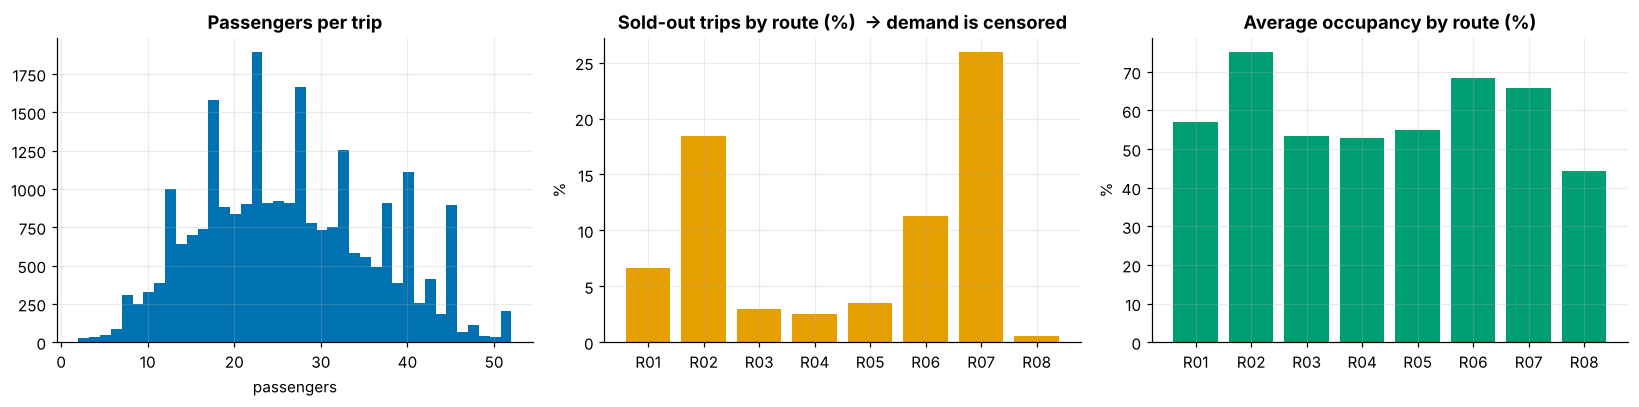

In [23]:
df["occ"] = df.passengers / df.capacity
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(df.passengers, bins=40, color=BLUE); ax[0].set_title("Passengers per trip"); ax[0].set_xlabel("passengers")
so = (df.passengers >= df.capacity).groupby(df.route_id).mean() * 100
ax[1].bar(so.index, so.values, color=ORANGE); ax[1].set_title("Sold-out trips by route (%)  → demand is censored"); ax[1].set_ylabel("%")
oc = df.groupby("route_id").occ.mean() * 100
ax[2].bar(oc.index, oc.values, color=GREEN); ax[2].set_title("Average occupancy by route (%)"); ax[2].set_ylabel("%")
savefig("eda_1_distributions")

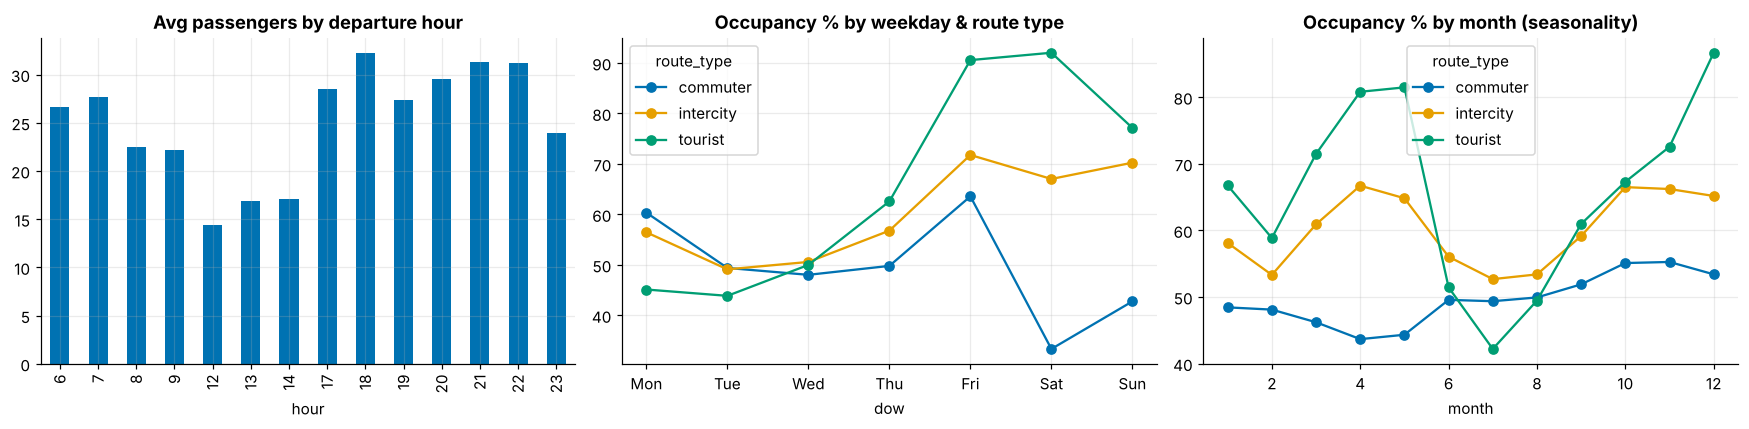

In [24]:
df["hour"] = df.departure_time.str[:2].astype(int)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("hour").passengers.mean().plot.bar(ax=ax[0], color=BLUE); ax[0].set_title("Avg passengers by departure hour"); ax[0].set_xlabel("hour")
(df.assign(dow=df.date.dt.dayofweek).groupby(["dow", "route_type"]).occ.mean().unstack() * 100).plot(ax=ax[1], marker="o", color=[BLUE, ORANGE, GREEN])
ax[1].set_xticks(range(7)); ax[1].set_xticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]); ax[1].set_title("Occupancy % by weekday & route type")
(df.assign(m=df.date.dt.month).groupby(["m", "route_type"]).occ.mean().unstack() * 100).plot(ax=ax[2], marker="o", color=[BLUE, ORANGE, GREEN])
ax[2].set_title("Occupancy % by month (seasonality)"); ax[2].set_xlabel("month")
savefig("eda_2_patterns")

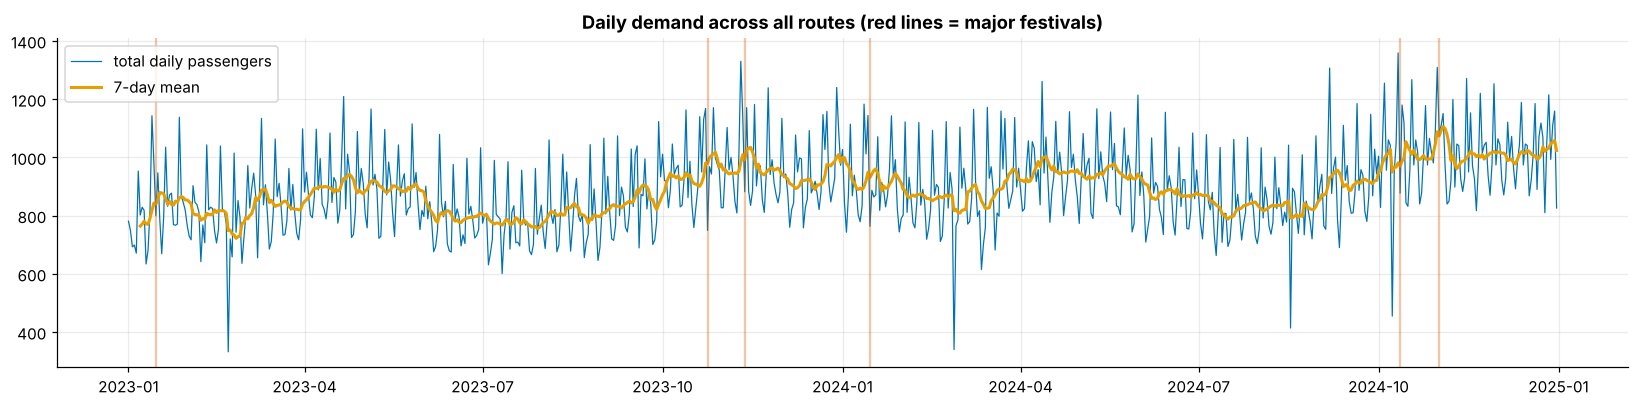

In [25]:
daily = df.groupby("date").passengers.sum()
fig, ax = plt.subplots(figsize=(15, 3.8))
ax.plot(daily.index, daily.values, color=BLUE, lw=.8, label="total daily passengers")
ax.plot(daily.rolling(7).mean(), color=ORANGE, lw=2, label="7-day mean")
for d, n, w in C.HOLIDAYS:
    if w >= 1.0 and pd.Timestamp(d) <= daily.index.max(): ax.axvline(pd.Timestamp(d), color=RED, alpha=.35)
ax.set_title("Daily demand across all routes (red lines = major festivals)"); ax.legend()
savefig("eda_3_timeseries")

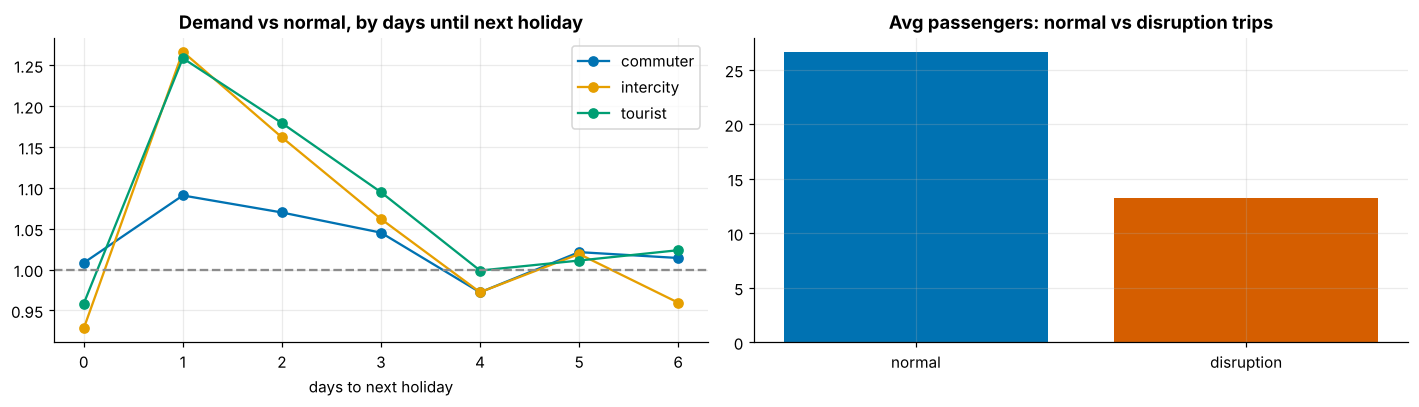

Disruption trips: 2.3% of rows, avg demand -50% vs normal


In [26]:
hf = holiday_features(df.date)
slot_mean = df.groupby(["route_id", "departure_time", df.date.dt.dayofweek]).passengers.transform("mean")
tmp = pd.DataFrame({"ratio": df.passengers / slot_mean, "d": hf.days_to_next_holiday, "type": df.route_type})
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for t, c in zip(["commuter", "intercity", "tourist"], [BLUE, ORANGE, GREEN]):
    g = tmp[(tmp.type == t) & (tmp.d <= 6)].groupby("d").ratio.mean()
    ax[0].plot(g.index, g.values, marker="o", color=c, label=t)
ax[0].axhline(1, color=GREY, ls="--"); ax[0].set_title("Demand vs normal, by days until next holiday"); ax[0].set_xlabel("days to next holiday"); ax[0].legend()
dis = df.groupby("disruption").passengers.mean()
ax[1].bar(["normal", "disruption"], dis.values, color=[BLUE, RED]); ax[1].set_title("Avg passengers: normal vs disruption trips")
savefig("eda_4_holiday_disruption")
print(f"Disruption trips: {df.disruption.mean()*100:.1f}% of rows, avg demand {dis[1]/dis[0]*100-100:.0f}% vs normal")

**EDA takeaways** → (1) strong weekday × route-type patterns (commuter vs weekend-leisure); (2) clear seasonality; (3) festival run-ups lift demand *before* the holiday, hence the features `days_to_next_holiday` and `next_holiday_weight`;
(4) ≈ 7 % of trips are sold out, so the target is **censored** at capacity; (5) disruptions cut demand 30–70 % but cannot be known 48 h ahead.

## 4. Leakage audit (what is allowed at forecast time T-48 h?)

In [27]:
audit = pd.DataFrame([
    ["route_id / route_type / distance_km / capacity", "yes – schedule master data", "✅ feature"],
    ["date, departure_time → weekday, month, season, peak", "yes – calendar", "✅ feature"],
    ["holiday calendar (days to next / since last, size)", "yes – published in advance", "✅ feature"],
    ["fare_inr", "yes – set by pricing rule from calendar, not from realised demand", "✅ feature (missing → train median)"],
    ["passengers of same route+slot ≥ 7 days earlier (lag_w1..w4)", "yes – already observed (7 d ≥ 2 d horizon)", "✅ feature"],
    ["passengers of the SAME trip (target)", "no", "🎯 target only"],
    ["passengers 1-2 days earlier / same-day bookings", "no / not reliably (inside horizon)", "⛔ not used"],
    ["revenue_inr  (= passengers × fare)", "no – computed from the target", "⛔ forbidden (leakage trap)"],
    ["disruption flag", "no – known only after the event", "⛔ forbidden (error analysis only)"],
], columns=["Column / information", "Known at T-48h?", "Decision"])
display(audit.style.hide(axis="index"))

Column / information,Known at T-48h?,Decision
route_id / route_type / distance_km / capacity,yes – schedule master data,✅ feature
"date, departure_time → weekday, month, season, peak",yes – calendar,✅ feature
"holiday calendar (days to next / since last, size)",yes – published in advance,✅ feature
fare_inr,"yes – set by pricing rule from calendar, not from realised demand",✅ feature (missing → train median)
passengers of same route+slot ≥ 7 days earlier (lag_w1..w4),yes – already observed (7 d ≥ 2 d horizon),✅ feature
passengers of the SAME trip (target),no,🎯 target only
passengers 1-2 days earlier / same-day bookings,no / not reliably (inside horizon),⛔ not used
revenue_inr (= passengers × fare),no – computed from the target,⛔ forbidden (leakage trap)
disruption flag,no – known only after the event,⛔ forbidden (error analysis only)


## 5. Chronological split & feature engineering

train 2023-01-29 → 2024-06-30   17,603 trips
val   2024-07-01 → 2024-09-30    3,121 trips
test  2024-10-01 → 2024-12-31    3,124 trips


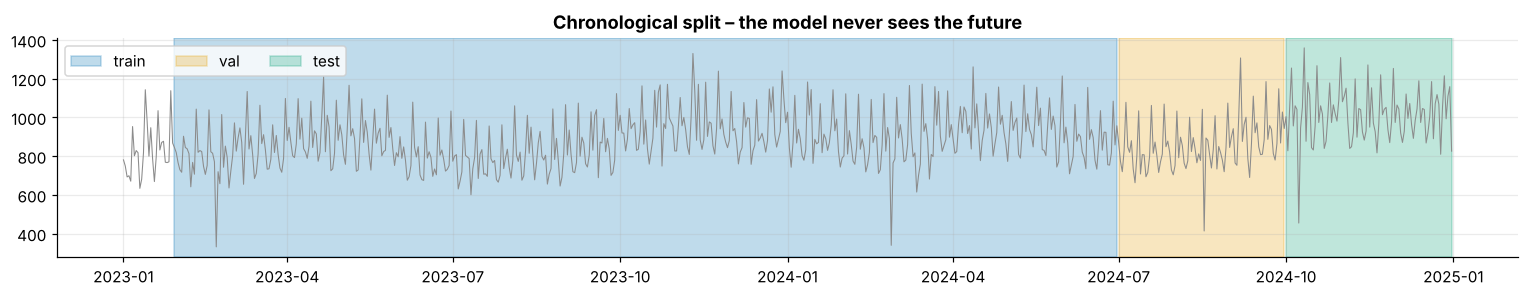

In [28]:
m = split_masks(df, C.TRAIN_END, C.VAL_END)
for k, v in m.items(): print(f"{k:5s} {df[v].date.min().date()} → {df[v].date.max().date()}   {v.sum():>6,} trips")
daily = df.groupby("date").passengers.sum()
fig, ax = plt.subplots(figsize=(14, 2.8)); ax.plot(daily.index, daily.values, color=GREY, lw=.7)
for k, col in zip(["train", "val", "test"], [BLUE, ORANGE, GREEN]):
    d = df[m[k]].date; ax.axvspan(d.min(), d.max(), color=col, alpha=.25, label=k)
ax.set_title("Chronological split – the model never sees the future"); ax.legend(ncol=3)
savefig("split")

In [29]:
fb = FeatureBuilder().fit(df[m["train"]])           # learns route table + median fares from TRAIN only
X = fb.transform(df, history=df)
print(len(fb.feature_names), "features:", fb.feature_names)
display(X[m["test"]].head(3).T.round(2))

38 features: ['capacity', 'distance_km', 'fare_inr', 'dep_hour', 'is_peak', 'dow', 'is_weekend', 'month', 'doy', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos', 'is_holiday', 'days_to_next_holiday', 'next_holiday_weight', 'days_since_prev_holiday', 'prev_holiday_weight', 'lag_w1', 'lag_w2', 'lag_w3', 'lag_w4', 'lag_mean_4', 'route_R01', 'route_R02', 'route_R03', 'route_R04', 'route_R05', 'route_R06', 'route_R07', 'route_R08', 'type_commuter', 'type_intercity', 'type_tourist', 'season_winter', 'season_summer', 'season_monsoon', 'season_festive']


,21674,21675,21676
capacity,45.00,45.00,45.00
distance_km,350.00,350.00,350.00
fare_inr,620.00,620.00,620.00
dep_hour,6.00,9.50,14.00
is_peak,1.00,1.00,0.00
dow,1.00,1.00,1.00
is_weekend,0.00,0.00,0.00
month,10.00,10.00,10.00
doy,275.00,275.00,275.00
dow_sin,0.78,0.78,0.78


**Feature groups** — *schedule*: capacity, distance, fare, departure hour, is_peak, route / type one-hots · *calendar*: weekday, month, day-of-year (+ sin/cos), weekend, season ·
*holiday*: is_holiday, days to next / since last, holiday size · *history (≥ 7 days old)*: same-slot demand 1, 2, 3, 4 weeks ago and their mean.
Lag construction (`add_lag_features`) looks up `date − 7·k` days only, so a row can never see its own or any future target (unit-tested).

## 6. Train, tune and compare models
`train.run()` executes the full repeatable pipeline: **clean → split → baselines → Ridge / RandomForest / LightGBM → LightGBM random-search tuned on the *validation* set (early stopping) → refit on train+val → single evaluation on the untouched *test* set → save artifact**.
Quantile LightGBM models (P10/P90) provide the 80 % prediction interval.

In [30]:
res = T.run()

data-quality report: {'rows_raw': 24871, 'duplicate_trips_removed': 37, 'negative_passengers_removed': 12, 'over_capacity_removed': 24, 'missing_fare_rows(imputed_later)': 124, 'rows_clean': 24798}
rows  train=17,603  val=3,121  test=3,124


best LightGBM params: {'num_leaves': 31, 'learning_rate': 0.05, 'min_child_samples': 20, 'colsample_bytree': 0.6, 'subsample': 0.9, 'reg_lambda': 0} iters: 363


saved artifact -> /tmp/claude-0/-home-claude/5677bd97-9fb0-5a7c-862b-188aeb1937e9/scratchpad/nbrun/bus-demand-forecasting/models/forecaster.joblib
                                    MAE  RMSE  WAPE_%  Bias
Baseline: route/time/weekday mean  5.99  7.51   20.08 -4.03
Baseline: same slot last week      6.62  8.71   22.21 -0.25
Ridge                              5.11  6.49   17.15 -0.58
RandomForest                       5.24  6.57   17.56 -1.06
LightGBM (tuned)                   5.00  6.32   16.78 -1.47


In [31]:
val_tbl = pd.DataFrame(res["results"]["val_scores"]).T.round(2)
test_tbl = pd.DataFrame(res["results"]["test_scores"]).T.round(2)
print("VALIDATION (used for model selection)"); display(val_tbl)
print("TEST (held out – reported once)"); display(test_tbl)
base = test_tbl.loc["Baseline: route/time/weekday mean"]
best = test_tbl.loc["LightGBM (tuned)"]
print(f"LightGBM vs required baseline on TEST →  MAE {best.MAE:.2f} vs {base.MAE:.2f} ({(1-best.MAE/base.MAE)*100:.0f}% better) | "
      f"RMSE {(1-best.RMSE/base.RMSE)*100:.0f}% better | WAPE {best['WAPE_%']:.1f}% vs {base['WAPE_%']:.1f}%")

VALIDATION (used for model selection)


,MAE,RMSE,WAPE_%,Bias
Baseline: route/time/weekday mean,5.17,6.58,20.44,0.64
Ridge,5.11,6.52,20.21,-0.24
RandomForest,5.11,6.48,20.19,-0.20
LightGBM (tuned),4.90,6.29,19.38,-0.64


TEST (held out – reported once)


,MAE,RMSE,WAPE_%,Bias
Baseline: route/time/weekday mean,5.99,7.51,20.08,-4.03
Baseline: same slot last week,6.62,8.71,22.21,-0.25
Ridge,5.11,6.49,17.15,-0.58
RandomForest,5.24,6.57,17.56,-1.06
LightGBM (tuned),5.00,6.32,16.78,-1.47


LightGBM vs required baseline on TEST →  MAE 5.00 vs 5.99 (17% better) | RMSE 16% better | WAPE 16.8% vs 20.1%


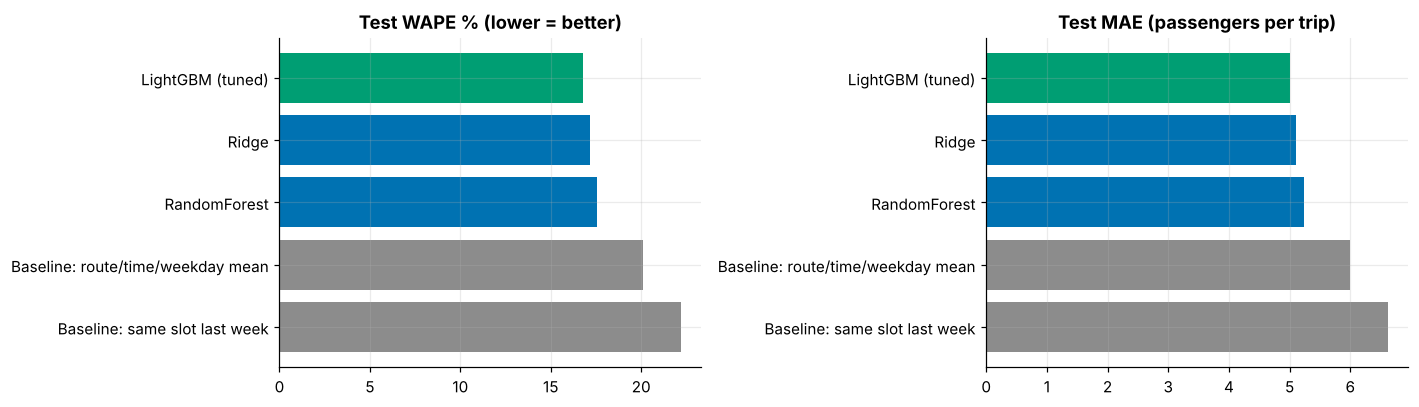

,num_leaves,learning_rate,min_child_samples,colsample_bytree,subsample,reg_lambda,best_iter,val_MAE
0,31,0.05,20,0.6,0.9,0,363,4.901
1,15,0.05,10,0.8,0.9,5,472,4.905
2,15,0.05,50,0.6,0.7,10,498,4.905
3,15,0.05,20,0.6,1.0,5,757,4.910
4,31,0.03,20,0.6,0.9,5,468,4.912


Chosen LightGBM params: {'num_leaves': 31, 'learning_rate': 0.05, 'min_child_samples': 20, 'colsample_bytree': 0.6, 'subsample': 0.9, 'reg_lambda': 0} | trees: 417


In [32]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
order = test_tbl.sort_values("WAPE_%")
cols = [GREY if "Baseline" in i else (GREEN if "LightGBM" in i else BLUE) for i in order.index]
ax[0].barh(order.index, order["WAPE_%"], color=cols); ax[0].invert_yaxis(); ax[0].set_title("Test WAPE % (lower = better)")
ax[1].barh(order.index, order["MAE"], color=cols); ax[1].invert_yaxis(); ax[1].set_title("Test MAE (passengers per trip)")
savefig("model_comparison")
display(res["tuning"].head(5).round(3))
print("Chosen LightGBM params:", res["results"]["best_params"], "| trees:", res["results"]["n_estimators_final"])

## 7. Error analysis (test set): per route, peak / off-peak, calendar, disruption

,route_id,n_trips,MAE,RMSE,WAPE_%,Bias,baseline_WAPE_%,WAPE_gain_pts
0,R01,459,4.85,6.02,16.42,-1.99,20.10,3.68
1,R02,275,4.81,5.89,12.68,-1.95,16.29,3.60
2,R03,644,5.58,7.00,17.78,-1.46,19.63,1.85
3,R04,368,5.24,6.55,19.13,-2.57,22.11,2.99
4,R05,367,5.18,6.48,18.89,-0.95,21.54,2.66
5,R06,276,4.65,5.69,15.17,-1.67,18.59,3.42
6,R07,275,3.93,5.64,12.72,-0.98,22.21,9.48
7,R08,460,4.97,6.31,19.34,-0.43,20.74,1.39


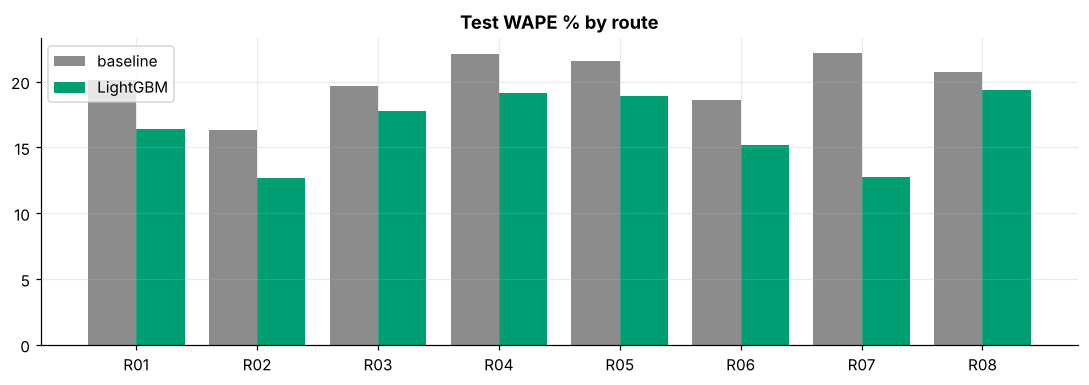

In [33]:
o = res["test_out"].copy()
Xte = res["X"].loc[o.index]
o["weekend"] = Xte["is_weekend"].values
o["holiday_window(±2d)"] = ((Xte["days_to_next_holiday"] <= 2) | (Xte["days_since_prev_holiday"] <= 2)).astype(int).values
o["abs_err"] = (o.passengers - o.pred).abs()

def compare(by):
    a = group_metrics(o, by, p="pred"); b = group_metrics(o, by, p="pred_baseline")
    out = a[[by if isinstance(by, str) else by[0], "n_trips", "MAE", "RMSE", "WAPE_%", "Bias"]].copy()
    out["baseline_WAPE_%"] = b["WAPE_%"].values
    out["WAPE_gain_pts"] = out["baseline_WAPE_%"] - out["WAPE_%"]
    return out.round(2)

by_route = compare("route_id"); display(by_route)
fig, ax = plt.subplots(figsize=(10, 3.6)); x = np.arange(len(by_route))
ax.bar(x - .2, by_route["baseline_WAPE_%"], .4, color=GREY, label="baseline"); ax.bar(x + .2, by_route["WAPE_%"], .4, color=GREEN, label="LightGBM")
ax.set_xticks(x); ax.set_xticklabels(by_route.route_id); ax.set_title("Test WAPE % by route"); ax.legend()
savefig("error_by_route")

In [34]:
o["period"] = np.where(o.is_peak == 1, "peak", "off-peak")
print("PEAK vs OFF-PEAK"); display(compare("period"))
print("WEEKEND vs WEEKDAY"); display(compare("weekend"))
print("HOLIDAY WINDOW (±2 days) vs normal"); display(compare("holiday_window(±2d)"))
print("DISRUPTION trips (unpredictable) vs normal"); display(compare("disruption"))

PEAK vs OFF-PEAK


,period,n_trips,MAE,RMSE,WAPE_%,Bias,baseline_WAPE_%,WAPE_gain_pts
0,off-peak,828,4.80,5.93,19.33,-1.25,21.65,2.32
1,peak,2296,5.08,6.46,16.05,-1.55,19.64,3.58


WEEKEND vs WEEKDAY


,weekend,n_trips,MAE,RMSE,WAPE_%,Bias,baseline_WAPE_%,WAPE_gain_pts
0,0,2243,5.23,6.55,17.65,-1.47,20.97,3.32
1,1,881,4.42,5.71,14.60,-1.48,17.87,3.27


HOLIDAY WINDOW (±2 days) vs normal


,holiday_window(±2d),n_trips,MAE,RMSE,WAPE_%,Bias,baseline_WAPE_%,WAPE_gain_pts
0,0,2376,4.98,6.32,17.06,-1.34,19.24,2.18
1,1,748,5.08,6.33,15.95,-1.92,22.54,6.58


DISRUPTION trips (unpredictable) vs normal


,disruption,n_trips,MAE,RMSE,WAPE_%,Bias,baseline_WAPE_%,WAPE_gain_pts
0,0,3050,4.83,6.06,15.99,-1.81,19.52,3.53
1,1,74,12.13,13.13,86.84,12.13,69.99,-16.84


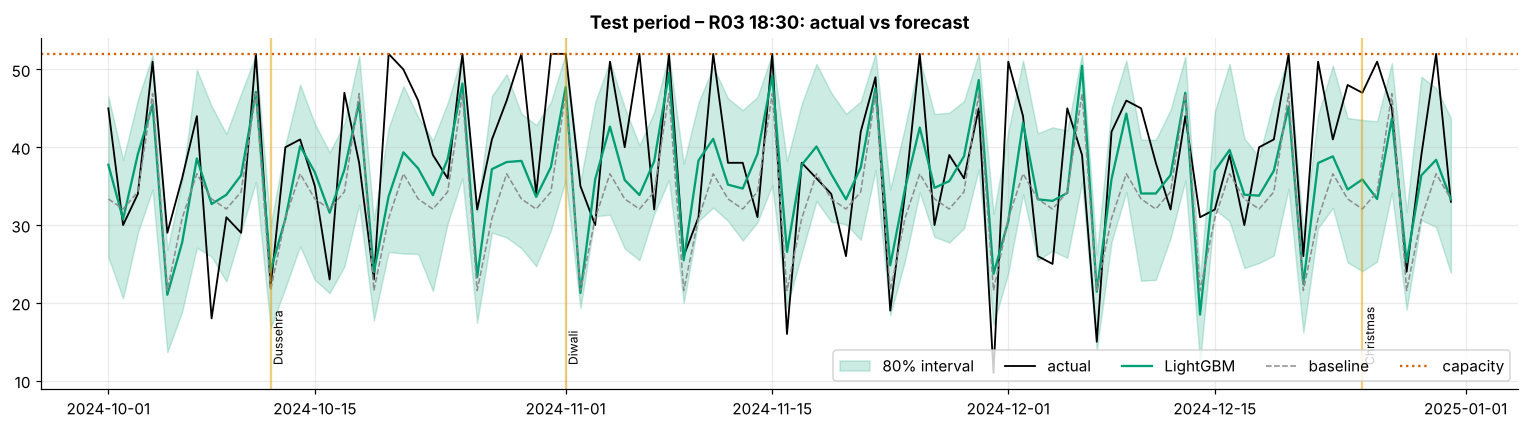

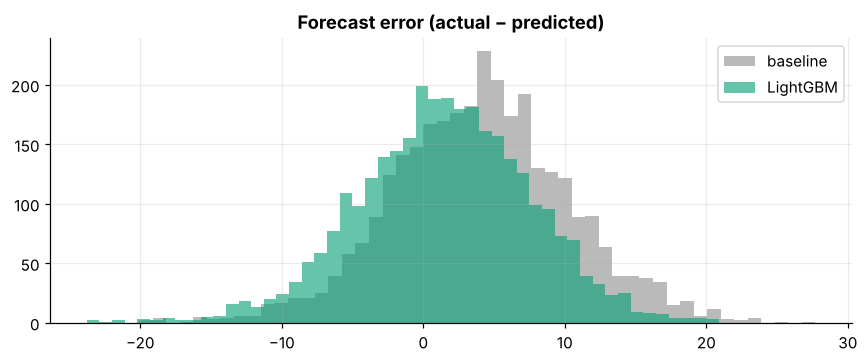

10 largest errors:


,route_id,date,departure_time,passengers,pred,disruption,holiday_window(±2d),capacity
21916,R01,2024-10-08,22:30,9,32.8,1,0,45
22852,R05,2024-11-04,22:30,10,33.6,1,0,45
22518,R07,2024-10-25,21:00,16,38.2,1,0,40
24047,R08,2024-12-09,06:30,17,38.4,1,0,52
24050,R08,2024-12-09,17:30,12,33.3,1,0,52
22778,R04,2024-11-02,08:00,45,24.1,0,1,45
24207,R05,2024-12-14,07:00,45,24.1,0,0,45
23759,R03,2024-12-01,18:30,51,30.5,0,0,52
22008,R07,2024-10-10,21:00,14,34.1,1,1,40
22674,R03,2024-10-30,20:00,12,31.7,0,1,52


In [35]:
rt, slot = "R03", "18:30"
g = o[(o.route_id == rt) & (o.departure_time == slot)].sort_values("date")
fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(g.date, g.p10, g.p90, color=GREEN, alpha=.2, label="80% interval")
ax.plot(g.date, g.passengers, color="black", lw=1.2, label="actual"); ax.plot(g.date, g.pred, color=GREEN, lw=1.5, label="LightGBM")
ax.plot(g.date, g.pred_baseline, color=GREY, lw=1, ls="--", label="baseline"); ax.axhline(g.capacity.iloc[0], color=RED, ls=":", label="capacity")
for d, n, w in C.HOLIDAYS:
    if g.date.min() <= pd.Timestamp(d) <= g.date.max() and w >= 0.8: ax.axvline(pd.Timestamp(d), color=ORANGE, alpha=.5); ax.text(pd.Timestamp(d), g.passengers.min() + 1, n, rotation=90, fontsize=8, va='bottom')
ax.set_title(f"Test period – {rt} {slot}: actual vs forecast"); ax.legend(ncol=5, loc="lower right")
savefig("actual_vs_pred")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(o.passengers - o.pred_baseline, bins=50, alpha=.6, color=GREY, label="baseline"); ax.hist(o.passengers - o.pred, bins=50, alpha=.6, color=GREEN, label="LightGBM")
ax.set_title("Forecast error (actual − predicted)"); ax.legend()
savefig("residuals")
print("10 largest errors:"); display(o.sort_values("abs_err", ascending=False).head(10)[["route_id","date","departure_time","passengers","pred","disruption","holiday_window(±2d)","capacity"]].round(1))

**How to read this** — LightGBM improves on the baseline on every route; the gain is largest where demand depends on festivals/weekends (tourist & intercity). Error is highest on **disruption trips** (events nobody could forecast 48 h ahead) and around holidays.
The model slightly **under-forecasts on average** (negative bias): sold-out buses are capped at capacity, so the training signal for the busiest trips is censored.

## 8. Uncertainty & capacity-aware flags

In [36]:
cov = res["results"]["interval_coverage_80"]
print(f"80% interval observed coverage on test: {cov*100:.1f}% (target 80%) | mean width {res['results']['mean_interval_width']:.1f} passengers")
print("  coverage on normal trips   :", round(interval_coverage(o[o.disruption==0].passengers, o[o.disruption==0].p10, o[o.disruption==0].p90)*100, 1), "%")
print("  coverage on disruption trips:", round(interval_coverage(o[o.disruption==1].passengers, o[o.disruption==1].p10, o[o.disruption==1].p90)*100, 1), "%")
print(o.flag.value_counts().to_string())

80% interval observed coverage on test: 72.9% (target 80%) | mean width 14.1 passengers
  coverage on normal trips   : 74.3 %
  coverage on disruption trips: 17.6 %
flag
NORMAL          2144
WATCH            509
ADD_CAPACITY     247
UNDER_USED       224


Task: catch trips that end up ≥90% full (623 of 3124 test trips)


,precision,recall,F1,alerts
LightGBM + interval flag,0.647,0.785,0.709,756.0
Baseline flag,0.729,0.592,0.654,506.0


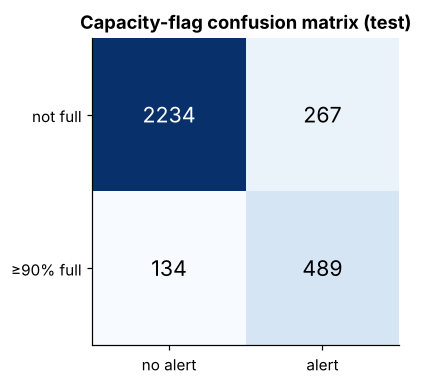

In [37]:
actual_high = (o.passengers >= C.HIGH_LOAD_ACTUAL * o.capacity)
model_alert = o.flag.isin(["ADD_CAPACITY", "WATCH"])
bflag = capacity_flags(o.pred_baseline, o.pred_baseline, o.capacity); base_alert = pd.Series(bflag, index=o.index).isin(["ADD_CAPACITY", "WATCH"])
tbl = pd.DataFrame({n: {"precision": precision_score(actual_high, a), "recall": recall_score(actual_high, a), "F1": f1_score(actual_high, a), "alerts": int(a.sum())}
                    for n, a in {"LightGBM + interval flag": model_alert, "Baseline flag": base_alert}.items()}).T.round(3)
print(f"Task: catch trips that end up ≥{int(C.HIGH_LOAD_ACTUAL*100)}% full ({actual_high.sum()} of {len(o)} test trips)"); display(tbl)
cm = confusion_matrix(actual_high, model_alert)
fig, ax = plt.subplots(figsize=(4.2, 3.6)); ax.imshow(cm, cmap="Blues"); ax.grid(False)
for i in range(2):
    for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["no alert", "alert"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["not full", "≥90% full"])
ax.set_title("Capacity-flag confusion matrix (test)"); savefig("flag_confusion")

## 9. Explainability: most influential inputs and one explained prediction

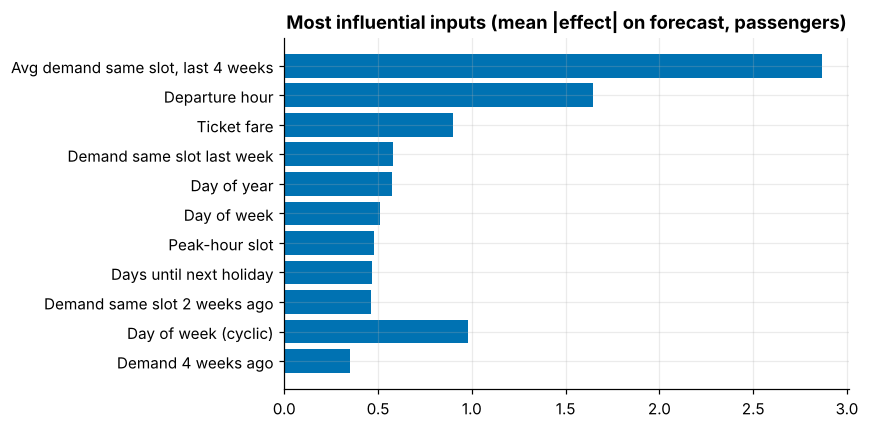

In [38]:
lgbm = res["models"]["LightGBM (tuned)"]
contrib = lgbm.booster_.predict(Xte, pred_contrib=True)          # exact SHAP values for tree models (passenger units)
names = list(Xte.columns)
imp = pd.Series(np.abs(contrib[:, :-1]).mean(0), index=names).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8, 4)); ax.barh([DISPLAY.get(n, n) for n in imp.index][::-1], imp.values[::-1], color=BLUE)
ax.set_title("Most influential inputs (mean |effect| on forecast, passengers)"); savefig("feature_importance")

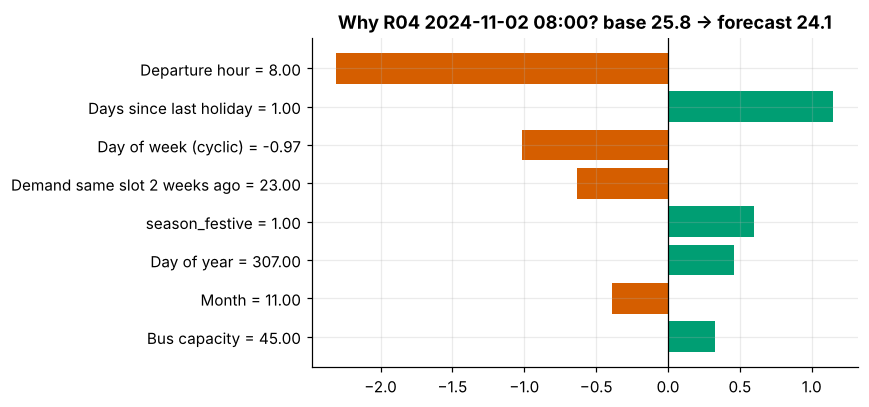

Actual = 45, forecast = 24.1 (80% interval 20.3–38.3), capacity 45
Context -> within ±2d of a holiday: True | lag_w1: 31.0 | days_to_next_holiday: 15.0 | days_since_prev_holiday: 1.0


In [39]:
case = o[o.disruption == 0].sort_values("abs_err").iloc[-1]       # largest error among NON-disruption trips
pos = o.index.get_loc(case.name); c = contrib[pos]
top = pd.Series(c[:-1], index=names).sort_values(key=abs, ascending=False).head(8)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh([f"{DISPLAY.get(n, n)} = {Xte.iloc[pos][n]:.2f}" for n in top.index][::-1], top.values[::-1], color=[GREEN if v > 0 else RED for v in top.values[::-1]])
ax.axvline(0, color="black", lw=.8); ax.set_title(f"Why {case.route_id} {case.date.date()} {case.departure_time}? base {c[-1]:.1f} → forecast {case.pred:.1f}")
savefig("explain_one_prediction")
print(f"Actual = {case.passengers}, forecast = {case.pred:.1f} (80% interval {case.p10:.1f}–{case.p90:.1f}), capacity {case.capacity}")
print("Context -> within ±2d of a holiday:", bool(case['holiday_window(±2d)']), "| lag_w1:", Xte.iloc[pos]['lag_w1'], "| days_to_next_holiday:", Xte.iloc[pos]['days_to_next_holiday'], "| days_since_prev_holiday:", Xte.iloc[pos]['days_since_prev_holiday'])

**Writing this up** — pick the case printed above and state: (1) what the model predicted and what happened, (2) which inputs pushed the forecast (green = up, red = down), (3) *why it was wrong* — typically a festival/long-weekend effect stronger than last week's history suggests, or a sold-out bus whose true demand is hidden by the capacity cap, and (4) what a planner should do (check bookings / look at the interval).

## 10. Robustness: rolling backtest and new-route stress test

,test_window,baseline_WAPE_%,lightgbm_WAPE_%
0,2024-04-01 .. 2024-07-01,19.34,17.57
1,2024-07-01 .. 2024-09-30,20.44,19.40
2,2024-10-01 .. 2024-12-31,20.08,16.79


,route_id,WAPE_%_known_route,WAPE_%_new_route,MAE_known,MAE_new
0,R01,16.4,18.4,4.9,5.4
1,R02,12.7,16.8,4.8,6.4
2,R03,17.8,26.8,5.6,8.4
3,R04,19.1,18.4,5.2,5.0
4,R05,18.9,20.1,5.2,5.5
5,R06,15.2,16.2,4.6,5.0
6,R07,12.7,21.3,3.9,6.6
7,R08,19.3,23.3,5.0,6.0


Average WAPE known route 16.5%  vs brand-new route 20.1%


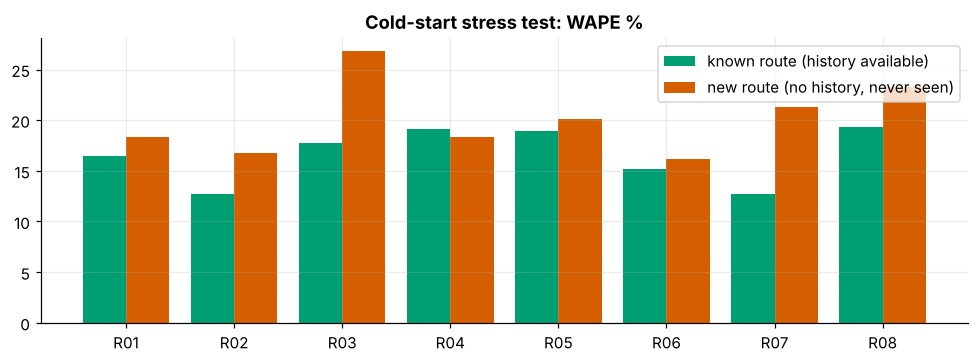

In [40]:
bt = rolling_backtest(res["df"], res["results"]["best_params"], res["results"]["n_estimators_final"])
display(bt.round(2))
cs = cold_start_experiment(res["df"], res["results"]["best_params"], res["results"]["n_estimators_final"], res["test_out"])
display(cs.round(1))
print(f"Average WAPE known route {cs['WAPE_%_known_route'].mean():.1f}%  vs brand-new route {cs['WAPE_%_new_route'].mean():.1f}%")
fig, ax = plt.subplots(figsize=(9, 3.4)); x = np.arange(len(cs))
ax.bar(x - .2, cs["WAPE_%_known_route"], .4, color=GREEN, label="known route (history available)"); ax.bar(x + .2, cs["WAPE_%_new_route"], .4, color=RED, label="new route (no history, never seen)")
ax.set_xticks(x); ax.set_xticklabels(cs.route_id); ax.set_title("Cold-start stress test: WAPE %"); ax.legend(); savefig("cold_start")

The gain over the baseline is stable across three rolling windows (not a lucky split). A route the model has never seen is forecast **noticeably worse**, so the app refuses unknown routes; note that synthetic routes share one generating process, so
real-world cold-start error would likely be *worse* than shown here.

## 11. Leakage demonstration & automated tests

In [41]:
leaky = res["X"].copy(); leaky["revenue_inr"] = res["df"]["revenue_inr"]       # forbidden: revenue = passengers × fare
trva = m["train"] | m["val"]
lk = T.make_lgbm(res["results"]["best_params"], 300).fit(leaky[trva], res["df"].loc[trva, "passengers"])
lk_m = regression_metrics(res["df"].loc[m["test"], "passengers"], lk.predict(leaky[m["test"]]))
print(f"WITH leaked revenue_inr  → test WAPE {lk_m['WAPE_%']:.2f}%   (suspiciously perfect!)")
print(f"HONEST pipeline          → test WAPE {best['WAPE_%']:.2f}%")
from src.features import FORBIDDEN_FEATURES
assert not set(FORBIDDEN_FEATURES) & set(res["X"].columns); print("✅ no forbidden column among the", res["X"].shape[1], "model inputs")

WITH leaked revenue_inr  → test WAPE 1.31%   (suspiciously perfect!)
HONEST pipeline          → test WAPE 16.78%
✅ no forbidden column among the 38 model inputs


In [42]:
!python -m pytest -q tests 2>&1 | tail -4

    eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
10 passed, 4 warnings in 3.91s


## 12. Inference through the saved artifact, and the app

In [43]:
fc = Forecaster(PROJECT)                      # loads models/forecaster.joblib + data/processed/history.csv (no hard-coded outputs)
a = fc.predict("R03", "2024-11-01", "18:30")  # eve of Diwali, held-out period
b = fc.predict("R07", "2025-01-03", "19:00")  # a future date beyond the data
for r in (a, b):
    print(f"{r['route_name']} {r['date']} {r['departure_time']}: {r['predicted_passengers']} pax (80% {r['interval_80']}) of {r['capacity']} → {r['flag']} | actual={r['actual_passengers_if_known']} | {r['date_location']}")
    print("   top drivers:", [(d['feature'], round(d['contribution_passengers'], 1)) for d in r['top_drivers'][:3]])
    print("   review notes:", *r["review_notes"][:-1], sep="\n     - ")

Mumbai - Pune 2024-11-01 18:30: 47.7 pax (80% [35.8, 52.0]) of 52 → ADD_CAPACITY | actual=52 | held-out test period
   top drivers: [('Avg demand same slot, last 4 weeks', 7.8), ('Departure hour', 2.3), ('Day of week (cyclic)', 1.9)]
   review notes:
     - Decision-support only: a planner must approve any capacity/schedule change.
     - Within 2 days of a holiday/festival - demand is volatile and the model has seen few such events.
Pune - Goa 2025-01-03 19:00: 38.7 pax (80% [36.3, 39.7]) of 40 → ADD_CAPACITY | actual=None | future date (no actuals)
   top drivers: [('Avg demand same slot, last 4 weeks', 5.6), ('Departure hour', 1.5), ('Demand same slot last week', 1.3)]
   review notes:
     - Decision-support only: a planner must approve any capacity/schedule change.


In [44]:
import importlib.util
spec = importlib.util.spec_from_file_location("busapp", PROJECT / "app" / "app.py")
busapp = importlib.util.module_from_spec(spec); spec.loader.exec_module(busapp)
md_out, fig_out, json_out = busapp.forecast("R03", "2024-11-01", "18:30", None)       # same function the UI button calls
print(md_out[:300]); plt.show()
if IN_COLAB:
    busapp.demo.launch(share=True, debug=False)       # opens a public link + inline app; record your demo video here
else:
    print("(Not in Colab – run `python app/app.py` locally to open the interface.)")

### Mumbai - Pune · 2024-11-01 · 18:30
**Forecast: 47.7 passengers** (80% interval 35.8 – 52.0) of 52 seats → **91.8% occupancy**

**🔴 ADD CAPACITY - likely full**

*Date is held-out test period.* Actual passengers: **52**.

**Human-review notes**
- Decision-support only: a planner must approve any 
(Not in Colab – run `python app/app.py` locally to open the interface.)


## 13. Limitations, bias, privacy, failure modes (copy into the report)
* **Synthetic data** — proves the pipeline, not real-world accuracy; real use needs licensed trip-level data and re-validation.
* **Censoring** — boarded passengers are capped at capacity, so true demand on sold-out trips is under-observed (negative bias on peaks). Mitigation in production: log refused/waitlisted demand.
* **Disruptions & unusual events** (strikes, floods, accidents, concerts) are unforecastable 48 h ahead → large errors (see §7). The app labels forecasts as advisory and lists review reasons.
* **New / changed routes & schedules** have no history → model refuses; stress test (§10) quantifies the extra error.
* **Calibration** — the 80 % interval covers ≈ 73 % of actuals: slightly over-confident.
* **Stale history** — forecasting weeks ahead shifts lags back; the app reports the shift and warns.
* **Representativeness / bias** — 8 routes, 2 years, one Diwali in training. Routes with little data or low-income corridors could be systematically under-served if forecasts were used to cut service automatically; therefore **human review is mandatory** and flags are advisory.
* **Privacy** — only aggregate trip counts; no passenger identifiers, names, payment or location traces are collected or needed.
* **Failure modes** — holiday definition changes (moving festival dates), pricing-policy changes (fare feature), data-feed outages (NaN lags) → monitor error weekly and retrain.

## 14. Package everything for submission

In [45]:
import shutil, json
summary = {"test_scores": res["results"]["test_scores"], "interval_coverage_80": cov, "flag_metrics": tbl.to_dict()}
(paths["reports"] / "summary_for_report.json").write_text(json.dumps(summary, indent=2, default=str))
shutil.make_archive("/content/bus-demand-forecasting" if IN_COLAB else "bus-demand-forecasting-export", "zip", PROJECT)
print("repo zipped. Files:")
!find . -maxdepth 2 -type f ! -name "*.pyc" | sort | head -60
if IN_COLAB:
    from google.colab import files; files.download("/content/bus-demand-forecasting.zip")

repo zipped. Files:
./.env.example
./.gitignore
./.pytest_cache/.gitignore
./.pytest_cache/CACHEDIR.TAG
./.pytest_cache/README.md
./README.md
./app/app.py
./bus-demand-forecasting-export.zip
./docs/architecture.md
./models/forecaster.joblib
./reports/lgbm_tuning.csv
./reports/metrics.json
./reports/summary_for_report.json
./reports/test_predictions.csv
./requirements.txt
./src/__init__.py
./src/config.py
./src/data_prep.py
./src/evaluate.py
./src/experiments.py
./src/features.py
./src/generate_data.py
./src/predict.py
./src/train.py
./tests/__init__.py
./tests/test_pipeline.py


### Push to GitHub (after unzipping locally)
```bash
cd bus-demand-forecasting && git init && git add . && git commit -m "Bus demand forecasting" 
git branch -M main && git remote add origin https://github.com/<you>/bus-demand-forecasting.git && git push -u origin main
```
Copy `Bus_Demand_Forecasting.ipynb` into `notebooks/`, then fill in the submission form (repo URL, final commit ID, video link, README link, AI attribution).